All enrichment uses **Fisher's exact test** (one-tailed, fragment-in vs fragment-out),  
Benjamini–Hochberg FDR correction, and the BRICS decomposition from RDKit.

SMILES source: `PUBCHEM_EXT_DATASOURCE_SMILES` from the result CSV files directly.

In [1]:
import pandas as pd
import numpy as np
import re
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

from rdkit import Chem
from rdkit.Chem import BRICS, Draw
from IPython.display import display, SVG

warnings.filterwarnings('ignore')

BASE    = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RES     = BASE + 'results/'
MITO    = RES  + 'casepase_mito_comparisons/'
CHOK1   = RES  + 'chok1_comparisons/'
HEPG2   = RES  + 'hepg2_comparisons/'

# ── SMILES lookup from result CSVs ──────────────────────────────────────────
def load_cid_smiles(path, extra_filter=None):
    """Load unique (CID, SMILES) pairs from a result CSV."""
    df = pd.read_csv(path,
                     usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                     low_memory=False)
    df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates('PUBCHEM_CID').reset_index(drop=True)
    return df[['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES']].rename(
        columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles'})

# ── BRICS helpers ────────────────────────────────────────────────────────────
def brics_frags(smiles):
    """Return frozenset of BRICS fragments for a SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    return frozenset(BRICS.BRICSDecompose(mol)) if mol else frozenset()

def clean_frag(frag_smi):
    """Remove BRICS dummy atoms so RDKit can render the fragment."""
    return re.sub(r'\[\d+\*\]', '[H]', frag_smi)

def fisher_enrichment(group_a_sets, group_b_sets, label_a='A', label_b='B',
                      min_count=3, fdr_alpha=0.05):
    """
    For every BRICS fragment, run Fisher's exact test:
      group_a_sets = list of frozensets (foreground)
      group_b_sets = list of frozensets (background)
    Returns DataFrame sorted by FDR-corrected p-value.
    """
    na, nb = len(group_a_sets), len(group_b_sets)
    all_frags = set().union(*group_a_sets, *group_b_sets)
    rows = []
    for frag in all_frags:
        a = sum(1 for fs in group_a_sets if frag in fs)   # foreground WITH frag
        c = sum(1 for fs in group_b_sets if frag in fs)   # background WITH frag
        if a < min_count:
            continue
        b, d = na - a, nb - c
        odds, pval = fisher_exact([[a, b], [c, d]], alternative='greater')
        rows.append({
            'fragment': frag,
            f'n_{label_a}': a,
            f'pct_{label_a}': 100 * a / na,
            f'n_{label_b}': c,
            f'pct_{label_b}': 100 * c / nb,
            'odds_ratio': odds,
            'pvalue': pval,
        })
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    _, padj, _, _ = multipletests(df['pvalue'], method='fdr_bh')
    df['padj'] = padj
    df = df[df['padj'] < fdr_alpha].sort_values('padj')
    return df.reset_index(drop=True)

def draw_frags(enrich_df, title, top_n=12, mols_per_row=4):
    """Draw top enriched BRICS fragments as a grid image."""
    mols, legs = [], []
    for _, row in enrich_df.head(top_n).iterrows():
        mol = Chem.MolFromSmiles(clean_frag(row['fragment']))
        if mol:
            mols.append(mol)
            or_ = row['odds_ratio']
            or_str = f'{or_:.1f}' if or_ != float('inf') else '>inf'
            legs.append(f"OR={or_str}  padj={row['padj']:.2e}")
    if not mols:
        print(f'No drawable fragments for: {title}')
        return
    svg = Draw.MolsToGridImage(mols, molsPerRow=mols_per_row,
                               subImgSize=(280, 230),
                               legends=legs, useSVG=True)
    print(f'\n{title} — top {len(mols)} enriched BRICS fragments:')
    display(svg)

def bar_enrichment(enrich_df, title, top_n=20):
    """Horizontal bar chart of odds ratios for top enriched fragments."""
    top = enrich_df.head(top_n).copy()
    if top.empty:
        print(f'No significant fragments for: {title}')
        return
    labels = [f[:45] for f in top['fragment']]
    colors = ['#d62728' if or_ >= 3 else '#ff7f0e'
              for or_ in top['odds_ratio']]
    fig, ax = plt.subplots(figsize=(10, max(5, 0.35 * len(top))))
    ax.barh(labels[::-1], top['odds_ratio'].values[::-1],
            color=colors[::-1])
    ax.axvline(1, color='black', linestyle='--', linewidth=0.8)
    ax.set_xlabel('Odds Ratio')
    ax.set_title(title, fontsize=11)
    red   = mpatches.Patch(color='#d62728', label='OR ≥ 3 (strongly enriched)')
    orange = mpatches.Patch(color='#ff7f0e', label='OR 1–3 (moderately enriched)')
    ax.legend(handles=[red, orange], fontsize=8)
    plt.tight_layout()
    plt.show()

print('Setup complete.')

Setup complete.


---
## Analysis A — Table 4: Caspase + Mito in HepG2

Pairwise outcome groups (unique CIDs), built directly from the current
cleaned summary-assay data (General Response G1/G2): MMP from the
PubChem MMP summary assay (AID 720637, 857 actives, InChIKey/CID-deduplicated,
score-averaged), Caspase-3/7 from AID 654 + AID 1347034 (HepG2, 282 actives).
This REPLACES the old pre-merged `caspase_and_mito_Active.csv` /
`caspase_inactive_and_mito_inactive.csv` files, which were built on the old
raw MMP assay (AID 720635, 1,412 actives) before the G1 switch.

**Question:** Which BRICS fragments are uniquely enriched in the both-active group?
These fragments signal structural motifs that trigger the caspase--mitochondrial apoptotic cascade.


In [2]:
# -- Table 4 groups built from the two HepG2 SUMMARY assays -------------------
#
#   Summary assay 1 : AID 720637  -- mitochondrial membrane potential (MMP)
#                                    + viability counter-screen, HepG2
#   Summary assay 2 : AID 654 + AID 1347034 -- caspase-3/7 activation, HepG2
#
# Both are CID-deduplicated and score-averaged (see the cleaning notebooks).
# AID 1347037 is deliberately NOT used here: that summary assay is CHO-K1,
# not HepG2.
#
# This replaces the old pre-merged caspase_and_mito_Active.csv /
# caspase_inactive_and_mito_inactive.csv files, which were built on the OLD
# raw MMP assay (AID_720635, 1,412 actives) before the switch to the PubChem
# MMP summary assay (AID_720637) in General Response G1.
MMP_CSV = '/Users/yamini/Desktop/projects/qsar casepase/qsar_prediction/Rebuttal/Summary_1_models/cleaning/AID_720637_cleaned.csv'
CASPASE_HEPG2_CSV = '/Users/yamini/Desktop/projects/qsar casepase/qsar_prediction/Rebuttal/summary_2_1437034/cleaning/AID_654_1347034_cleaned.csv'

def load_active_inactive(path):
    df = pd.read_csv(path, usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES', 'PUBCHEM_ACTIVITY_OUTCOME'])
    df = df.dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df = df[df['PUBCHEM_ACTIVITY_OUTCOME'].isin(['Active', 'Inactive'])].copy()
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates('PUBCHEM_CID').reset_index(drop=True)
    return df.rename(columns={'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles',
                               'PUBCHEM_ACTIVITY_OUTCOME': 'outcome'})[['PUBCHEM_CID', 'smiles', 'outcome']]

mmp_df = load_active_inactive(MMP_CSV)
caspase_df = load_active_inactive(CASPASE_HEPG2_CSV)
print(f'Summary assay 1 - MMP/mitochondrial (AID 720637, HepG2) : {len(mmp_df):,} Active/Inactive compounds')
print(f'Summary assay 2 - Caspase-3/7 (AID 654+1347034, HepG2)  : {len(caspase_df):,} Active/Inactive compounds')

merged = mmp_df.merge(caspase_df, on='PUBCHEM_CID', suffixes=('_mmp', '_caspase'))
print(f'Compounds tested in both assays: {len(merged):,}')

both_active   = merged[(merged['outcome_mmp'] == 'Active')   & (merged['outcome_caspase'] == 'Active')]
both_inactive = merged[(merged['outcome_mmp'] == 'Inactive') & (merged['outcome_caspase'] == 'Inactive')]
caspase_only  = merged[(merged['outcome_mmp'] == 'Inactive') & (merged['outcome_caspase'] == 'Active')]
mito_only     = merged[(merged['outcome_mmp'] == 'Active')   & (merged['outcome_caspase'] == 'Inactive')]

n_total = len(merged)
print(f"Dual-active   (caspase+ / mito+) : {len(both_active):5,} ({100*len(both_active)/n_total:5.1f}%)")
print(f"Dual-inactive (caspase- / mito-) : {len(both_inactive):5,} ({100*len(both_inactive)/n_total:5.1f}%)")
print(f"Caspase-only                     : {len(caspase_only):5,} ({100*len(caspase_only)/n_total:5.1f}%)")
print(f"Mito-only                        : {len(mito_only):5,} ({100*len(mito_only)/n_total:5.1f}%)")

t4_active   = both_active[['PUBCHEM_CID', 'smiles_mmp']].rename(columns={'smiles_mmp': 'smiles'})
t4_inactive = both_inactive[['PUBCHEM_CID', 'smiles_mmp']].rename(columns={'smiles_mmp': 'smiles'})

# -- BRICS fragment sets --
t4_active_sets   = [brics_frags(s) for s in t4_active['smiles']]
t4_inactive_sets = [brics_frags(s) for s in t4_inactive['smiles']]

# -- Top BRICS fragments IN both-active (frequency) --
all_t4_frags = Counter()
for fs in t4_active_sets:
    all_t4_frags.update(fs)

print(f"\nTotal unique BRICS fragments in both-active group: {len(all_t4_frags)}")
print("\nTop 15 most frequent fragments (by compound count):")
for frag, cnt in all_t4_frags.most_common(15):
    pct = 100 * cnt / len(t4_active)
    print(f"  {cnt:3d} ({pct:4.1f}%)  {frag}")


Summary assay 1 - MMP/mitochondrial (AID 720637, HepG2) : 5,937 Active/Inactive compounds
Summary assay 2 - Caspase-3/7 (AID 654+1347034, HepG2)  : 7,285 Active/Inactive compounds
Compounds tested in both assays: 4,879
Dual-active   (caspase+ / mito+) :   106 (  2.2%)
Dual-inactive (caspase- / mito-) : 4,242 ( 86.9%)
Caspase-only                     :    20 (  0.4%)
Mito-only                        :   511 ( 10.5%)


[16:40:04] WARNING: not removing hydrogen atom without neighbors



Total unique BRICS fragments in both-active group: 176

Top 15 most frequent fragments (by compound count):
   18 (17.0%)  [3*]O[3*]
   13 (12.3%)  [16*]c1ccccc1
   11 (10.4%)  [16*]c1ccc([16*])cc1
   11 (10.4%)  [16*]c1ccc(O)cc1
   10 ( 9.4%)  [3*]OC
    7 ( 6.6%)  [16*]c1ccc(O)c([16*])c1
    7 ( 6.6%)  [8*]CCCCCCCCCCCC
    6 ( 5.7%)  [1*]C([6*])=O
    6 ( 5.7%)  [9*]n1cc[n+](C)c1
    5 ( 4.7%)  [8*]C(C)(C)C
    5 ( 4.7%)  [4*]CC
    5 ( 4.7%)  [4*]C[8*]
    5 ( 4.7%)  [7*]C[8*]
    5 ( 4.7%)  [5*]N[5*]
    4 ( 3.8%)  [8*]C(C)C


In [3]:
# ── Fisher's test: both-active vs both-inactive ──────────────────────────────
enrich_t4 = fisher_enrichment(
    t4_active_sets, t4_inactive_sets,
    label_a='active', label_b='inactive',
    min_count=3, fdr_alpha=0.05
)

print(f'Significantly enriched fragments in Both-Active vs Both-Inactive: {len(enrich_t4)}')
if not enrich_t4.empty:
    cols = ['fragment','n_active','pct_active','n_inactive','pct_inactive','odds_ratio','padj']
    print(enrich_t4[cols].head(15).to_string(index=False))

Significantly enriched fragments in Both-Active vs Both-Inactive: 12
                               fragment  n_active  pct_active  n_inactive  pct_inactive  odds_ratio         padj
                       [8*]CCCCCCCCCCCC         7    6.603774           3      0.070721   99.909091 7.017571e-09
                       [16*]c1ccc(O)cc1        11   10.377358          26      0.612918   18.775709 7.017571e-09
                [16*]c1ccc(O)c([16*])c1         7    6.603774           8      0.188590   37.421717 1.994150e-07
[3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC         3    2.830189           0      0.000000         inf 7.327620e-05
               [16*]c1cc([16*])c(O)cc1C         3    2.830189           0      0.000000         inf 7.327620e-05
                      [9*]n1cc[n+](C)c1         6    5.660377          32      0.754361    7.893750 1.155668e-03
                     [5*][N+]([5*])(C)C         3    2.830189           5      0.117869   24.681553 2.680093e-03
                           

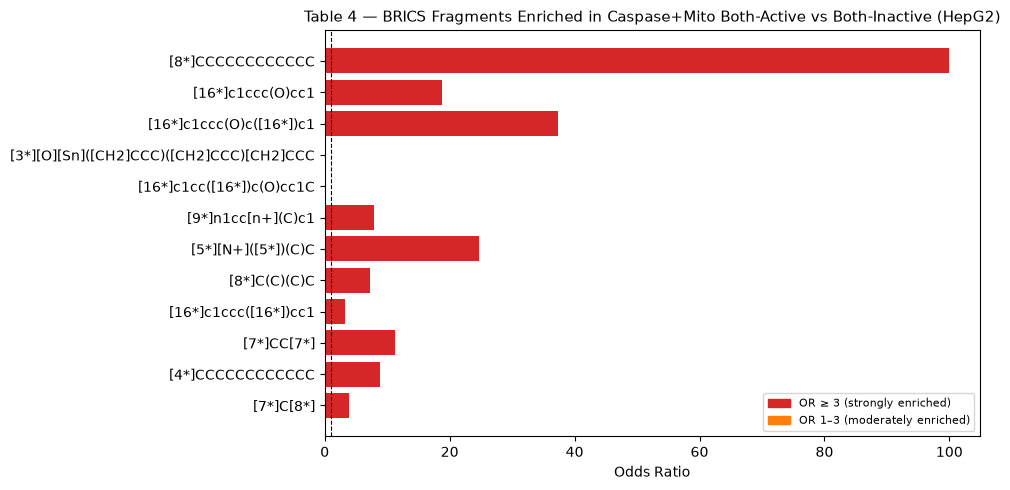


Table 4 — Top Enriched BRICS Fragments (Both-Active, HepG2) — top 12 enriched BRICS fragments:


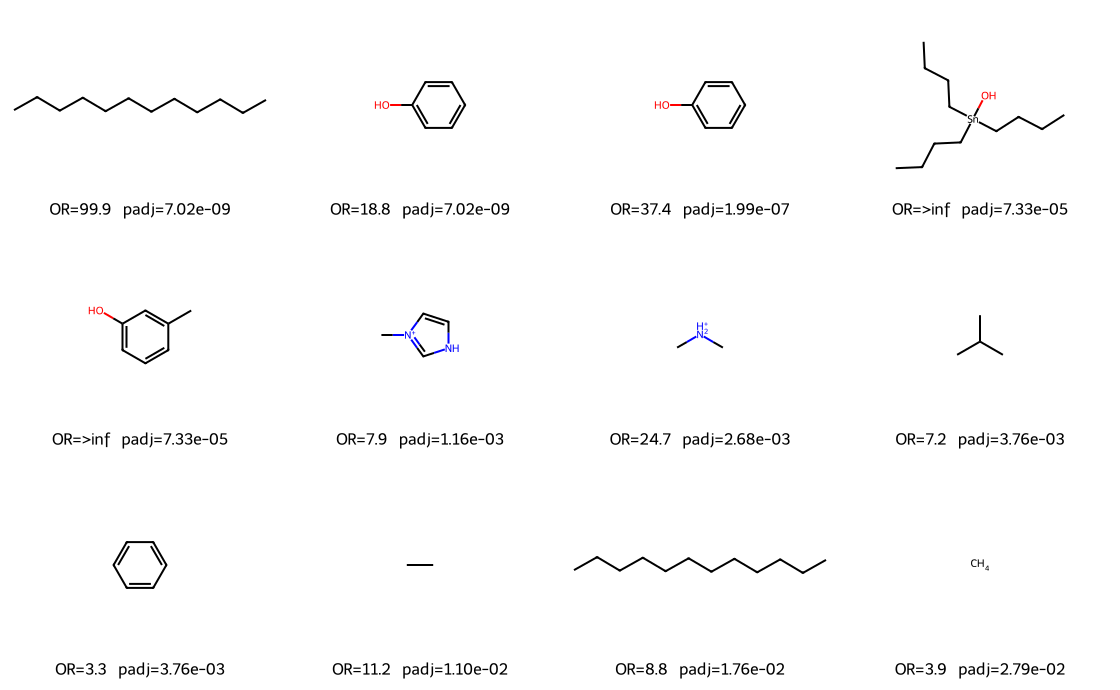

In [4]:
# ── Bar chart ────────────────────────────────────────────────────────────────
bar_enrichment(
    enrich_t4,
    title='Table 4 — BRICS Fragments Enriched in Caspase+Mito Both-Active vs Both-Inactive (HepG2)'
)

# ── Structure grid ───────────────────────────────────────────────────────────
draw_frags(
    enrich_t4,
    title='Table 4 — Top Enriched BRICS Fragments (Both-Active, HepG2)'
)

### Figure 8 — enriched BRICS fragments, drawn and grouped by structural family

Every BRICS fragment significantly enriched in **dual-active** (caspase-3/7 **+** mitochondrial) versus **dual-inactive** compounds, drawn as a structure and grouped by structural family. Groups come from the two HepG2 summary assays: **summary assay 1** (AID 720637, MMP) and **summary assay 2** (AID 654 + AID 1347034, caspase-3/7).

BRICS attachment points are shown as `*`. Every fragment is drawn at the same bond length, so sizes are comparable across panels. Full statistics — odds ratios, adjusted p-values and per-group prevalence counts — are written to `figure8_enrichment_table.csv`.

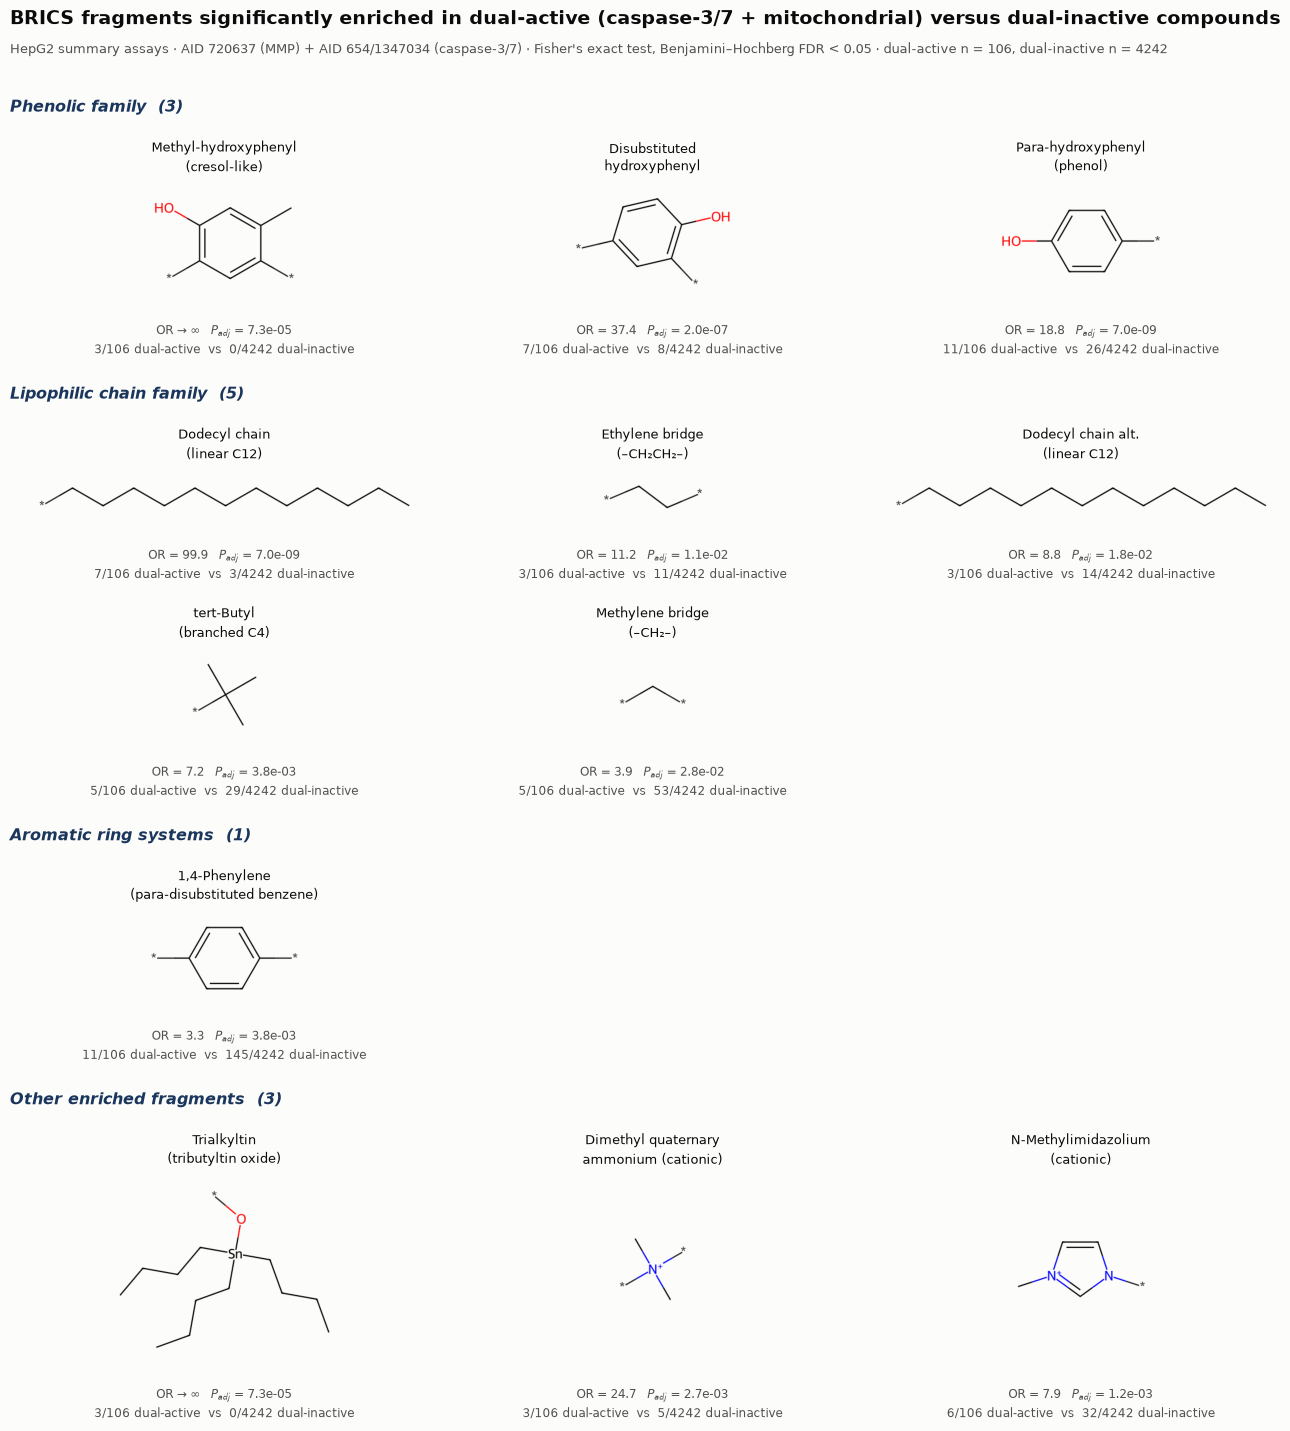


Figure 8: 12 significantly enriched fragments across 4 structural families  (figure 13.4 x 14.86 in).
Dual-active n = 106;  dual-inactive n = 4242.
Saved: figure8_brics_fragment_structures.png / .pdf, figure8_enrichment_table.csv


In [5]:
# ── Figure 8 — enriched BRICS fragments drawn and grouped by structural family ──
# Each fragment is rendered with RDKit at a single shared bond length, cropped to its
# own ink, and placed in a panel sized to the molecule. BRICS attachment points are
# drawn as plain '*'.
import io
from PIL import Image
from rdkit.Chem.Draw import rdMolDraw2D

N_ACT, N_INACT = len(t4_active), len(t4_inactive)

FRAG_NAME = {
    '[16*]c1ccc(O)cc1'                        : 'Para-hydroxyphenyl\n(phenol)',
    '[16*]c1ccc(O)c([16*])c1'                 : 'Disubstituted\nhydroxyphenyl',
    '[16*]c1cc([16*])c(O)cc1C'                : 'Methyl-hydroxyphenyl\n(cresol-like)',
    '[8*]CCCCCCCCCCCC'                        : 'Dodecyl chain\n(linear C12)',
    '[4*]CCCCCCCCCCCC'                        : 'Dodecyl chain alt.\n(linear C12)',
    '[8*]C(C)(C)C'                            : 'tert-Butyl\n(branched C4)',
    '[7*]CC[7*]'                              : 'Ethylene bridge\n(–CH₂CH₂–)',
    '[7*]C[8*]'                               : 'Methylene bridge\n(–CH₂–)',
    '[16*]c1ccc([16*])cc1'                    : '1,4-Phenylene\n(para-disubstituted benzene)',
    '[3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC' : 'Trialkyltin\n(tributyltin oxide)',
    '[9*]n1cc[n+](C)c1'                       : 'N-Methylimidazolium\n(cationic)',
    '[5*][N+]([5*])(C)C'                      : 'Dimethyl quaternary\nammonium (cationic)',
}
FRAG_FAMILY = {
    '[16*]c1ccc(O)cc1'                        : 'Phenolic family',
    '[16*]c1ccc(O)c([16*])c1'                 : 'Phenolic family',
    '[16*]c1cc([16*])c(O)cc1C'                : 'Phenolic family',
    '[8*]CCCCCCCCCCCC'                        : 'Lipophilic chain family',
    '[4*]CCCCCCCCCCCC'                        : 'Lipophilic chain family',
    '[8*]C(C)(C)C'                            : 'Lipophilic chain family',
    '[7*]CC[7*]'                              : 'Lipophilic chain family',
    '[7*]C[8*]'                               : 'Lipophilic chain family',
    '[16*]c1ccc([16*])cc1'                    : 'Aromatic ring systems',
    '[3*][O][Sn]([CH2]CCC)([CH2]CCC)[CH2]CCC' : 'Other enriched fragments',
    '[9*]n1cc[n+](C)c1'                       : 'Other enriched fragments',
    '[5*][N+]([5*])(C)C'                      : 'Other enriched fragments',
}
FAM_ORDER = ['Phenolic family', 'Lipophilic chain family',
             'Aromatic ring systems', 'Other enriched fragments']

SURFACE, INK, MUTED, NAVY = '#fcfcfb', '#0b0b0b', '#52514e', '#1b365d'
BG = (0.988, 0.988, 0.984, 1.0)

fig8 = enrich_t4.copy()
fig8['name']   = [FRAG_NAME.get(f, f)   for f in fig8['fragment']]
fig8['family'] = [FRAG_FAMILY.get(f, 'Other enriched fragments') for f in fig8['fragment']]
unmapped = [f for f in fig8['fragment'] if f not in FRAG_FAMILY]
if unmapped:
    print('NOTE - fragments with no hand-assigned family (placed in "Other"):')
    for f in unmapped:
        print('   ', f)

def render_frag(frag, canvas=(1700, 1200), bond=42.0):
    """BRICS fragment -> tightly cropped RGB array, drawn at a fixed bond length."""
    smi = re.sub(r'\[\d+\*\]', '[*]', frag)       # isotopic dummies -> plain '*'
    mol = Chem.MolFromSmiles(smi)
    d = rdMolDraw2D.MolDraw2DCairo(*canvas)
    o = d.drawOptions()
    o.setBackgroundColour(BG)
    o.bondLineWidth = 2.2
    o.fixedBondLength = bond
    o.minFontSize, o.maxFontSize = 17, 24
    rdMolDraw2D.PrepareAndDrawMolecule(d, mol)
    d.FinishDrawing()
    im = Image.open(io.BytesIO(d.GetDrawingText())).convert('RGB')
    arr = np.array(im)
    ys, xs = np.where(arr.astype(int).sum(2) < 740)       # non-background ink
    if len(xs) == 0:
        return arr
    pad = 14
    return np.array(im.crop((max(xs.min()-pad, 0), max(ys.min()-pad, 0),
                             min(xs.max()+pad, arr.shape[1]),
                             min(ys.max()+pad, arr.shape[0]))))

NCOL = 3
HDR_H, NAME_H, STAT_H, GAP = 0.46, 0.62, 0.56, 0.22
FIG_W, LEFT, RIGHT, TOP, BOT = 13.4, 0.30, 0.25, 1.05, 0.30
col_w = (FIG_W - LEFT - RIGHT) / NCOL

frag_imgs = {f: render_frag(f) for f in fig8['fragment']}
# one scale for the whole figure: the widest fragment fills 90% of a column
PPI = max(a.shape[1] for a in frag_imgs.values()) / (col_w * 0.90)

blocks = []
for fam in FAM_ORDER:
    sub = fig8[fig8.family == fam].sort_values('odds_ratio', ascending=False).reset_index(drop=True)
    if sub.empty:
        continue
    sub['img']  = [frag_imgs[f] for f in sub['fragment']]
    sub['w_in'] = [a.shape[1] / PPI for a in sub['img']]
    sub['h_in'] = [a.shape[0] / PPI for a in sub['img']]
    blocks.append((fam, sub))

plan, FIG_H = [], TOP + BOT
for fam, sub in blocks:
    FIG_H += HDR_H
    rows = []
    for s in range(0, len(sub), NCOL):
        chunk = sub.iloc[s:s+NCOL]
        rh = NAME_H + chunk['h_in'].max() + STAT_H + GAP
        rows.append((chunk, rh))
        FIG_H += rh
    plan.append((fam, rows))

fig = plt.figure(figsize=(FIG_W, FIG_H))
fig.patch.set_facecolor(SURFACE)
fig.text(LEFT/FIG_W, (FIG_H-0.42)/FIG_H,
         'BRICS fragments significantly enriched in dual-active '
         '(caspase-3/7 + mitochondrial) versus dual-inactive compounds',
         fontsize=13.5, fontweight='bold', color=INK, ha='left', va='center')
fig.text(LEFT/FIG_W, (FIG_H-0.72)/FIG_H,
         f'HepG2 summary assays · AID 720637 (MMP) + AID 654/1347034 (caspase-3/7) · '
         f"Fisher's exact test, Benjamini–Hochberg FDR < 0.05 · "
         f'dual-active n = {N_ACT}, dual-inactive n = {N_INACT}',
         fontsize=9.6, color=MUTED, ha='left', va='center')

y = FIG_H - TOP
for fam, rows in plan:
    n_fam = sum(len(c) for c, _ in rows)
    fig.text(LEFT/FIG_W, (y - HDR_H*0.55)/FIG_H, f'{fam}  ({n_fam})',
             fontsize=11.5, fontweight='bold', style='italic',
             color=NAVY, ha='left', va='center')
    y -= HDR_H
    for chunk, rh in rows:
        imax = chunk['h_in'].max()
        for i, (_, r) in enumerate(chunk.iterrows()):
            cx = LEFT + i*col_w + col_w*0.5
            fig.text(cx/FIG_W, (y-0.10)/FIG_H, r['name'], fontsize=9.6,
                     color=INK, ha='center', va='top', linespacing=1.4)
            ax = fig.add_axes([(cx - r['w_in']/2)/FIG_W,
                               (y - NAME_H - imax/2 - r['h_in']/2)/FIG_H,
                               r['w_in']/FIG_W, r['h_in']/FIG_H])
            ax.imshow(r['img']); ax.axis('off')
            or_txt = 'OR → ∞' if np.isinf(r['odds_ratio']) else f"OR = {r['odds_ratio']:,.1f}"
            fig.text(cx/FIG_W, (y - rh + GAP*0.55)/FIG_H,
                     f"{or_txt}   $P_{{adj}}$ = {r['padj']:.1e}\n"
                     f"{r['n_active']}/{N_ACT} dual-active  vs  "
                     f"{r['n_inactive']}/{N_INACT} dual-inactive",
                     fontsize=8.3, color=MUTED, ha='center', va='bottom', linespacing=1.45)
        y -= rh

fig.savefig('figure8_brics_fragment_structures.png', dpi=300,
            facecolor=SURFACE, bbox_inches='tight')
fig.savefig('figure8_brics_fragment_structures.pdf',
            facecolor=SURFACE, bbox_inches='tight')
plt.show()

# -- companion statistics table (odds ratios, adjusted p, per-group counts) --
fig8_table = fig8[['family', 'name', 'fragment', 'n_active', 'pct_active',
                   'n_inactive', 'pct_inactive', 'odds_ratio', 'pvalue', 'padj']].copy()
fig8_table['name']   = fig8_table['name'].str.replace('\n', ' ', regex=False)
fig8_table['family'] = pd.Categorical(fig8_table['family'], categories=FAM_ORDER, ordered=True)
fig8_table = fig8_table.sort_values(['family', 'odds_ratio'], ascending=[True, False])
fig8_table.to_csv('figure8_enrichment_table.csv', index=False)

print(f'\nFigure 8: {len(fig8)} significantly enriched fragments across '
      f'{len(plan)} structural families  (figure {FIG_W:.1f} x {FIG_H:.2f} in).')
print(f'Dual-active n = {N_ACT};  dual-inactive n = {N_INACT}.')
print('Saved: figure8_brics_fragment_structures.png / .pdf, figure8_enrichment_table.csv')


In [6]:
# ── Reverse direction: fragments enriched in BOTH-INACTIVE ──────────────────
# (i.e., fragments that are depleted / avoided in both-active compounds)
enrich_t4_inv = fisher_enrichment(
    t4_inactive_sets, t4_active_sets,
    label_a='inactive', label_b='active',
    min_count=15, fdr_alpha=0.05  # ~0.57% floor on 2628 inactive compounds
)

print(f'Fragments enriched in Both-INACTIVE (depleted in both-active): {len(enrich_t4_inv)}')
if not enrich_t4_inv.empty:
    print(enrich_t4_inv[['fragment','n_inactive','pct_inactive','n_active','pct_active','odds_ratio','padj']].head(15).to_string(index=False))

bar_enrichment(
    enrich_t4_inv,
    title='Table 4 — Fragments Enriched in Both-INACTIVE (i.e., absent from both-active, HepG2)'
)
draw_frags(
    enrich_t4_inv,
    title='Table 4 — Top Enriched Fragments in Both-Inactive'
)

Fragments enriched in Both-INACTIVE (depleted in both-active): 0
No significant fragments for: Table 4 — Fragments Enriched in Both-INACTIVE (i.e., absent from both-active, HepG2)
No drawable fragments for: Table 4 — Top Enriched Fragments in Both-Inactive


---
## Analysis B — Tables 6 & 7: CHO-K1 vs HepG2 "Both Active" Overlap

Caspase-3/7 + cell-viability **both active** in:

| Group | Definition | N |
|-------|-----------|---|
| **X — Common** | Active in both CHO-K1 AND HepG2 | 65 |
| **Y — CHO-K1 only** | Active in CHO-K1 both-active but NOT in HepG2 both-active | 42 |
| **Z — HepG2 only** | Active in HepG2 both-active but NOT in CHO-K1 both-active | 86 |

**Questions:**
- What fragments define Y (CHO-K1 selectivity) compared to X (common activity)?
- What fragments define Z (HepG2 selectivity) compared to X (common activity)?

In [6]:
# ── Load Table 6 (CHO-K1 both-active) and Table 7 (HepG2 both-active) ───────
chok1_df = load_cid_smiles(CHOK1 + 'chok1_casepase_and_casepase_viability_active.csv')
hepg2_df = load_cid_smiles(HEPG2 + 'hepg2_casepase_and_casepase_viability_active.csv')

chok1_cids = set(chok1_df['PUBCHEM_CID'])
hepg2_cids = set(hepg2_df['PUBCHEM_CID'])

common_cids  = chok1_cids & hepg2_cids            # X
chok1_only_cids = chok1_cids - hepg2_cids          # Y
hepg2_only_cids = hepg2_cids - chok1_cids          # Z

print(f'CHO-K1 both-active (Table 6) : {len(chok1_cids):3d} compounds')
print(f'HepG2  both-active (Table 7) : {len(hepg2_cids):3d} compounds')
print(f'X — Common                   : {len(common_cids):3d} compounds')
print(f'Y — CHO-K1 only              : {len(chok1_only_cids):3d} compounds')
print(f'Z — HepG2  only              : {len(hepg2_only_cids):3d} compounds')

# Build SMILES lookup across both files
smiles_lookup = pd.concat([chok1_df, hepg2_df]).drop_duplicates('PUBCHEM_CID').set_index('PUBCHEM_CID')['smiles']

def cids_to_sets(cids):
    return [brics_frags(smiles_lookup[cid]) for cid in cids if cid in smiles_lookup.index]

X_sets = cids_to_sets(common_cids)
Y_sets = cids_to_sets(chok1_only_cids)
Z_sets = cids_to_sets(hepg2_only_cids)

print(f'\nFrag sets computed — X: {len(X_sets)}, Y: {len(Y_sets)}, Z: {len(Z_sets)}')

CHO-K1 both-active (Table 6) : 107 compounds
HepG2  both-active (Table 7) : 151 compounds
X — Common                   :  65 compounds
Y — CHO-K1 only              :  42 compounds
Z — HepG2  only              :  86 compounds

Frag sets computed — X: 65, Y: 42, Z: 86


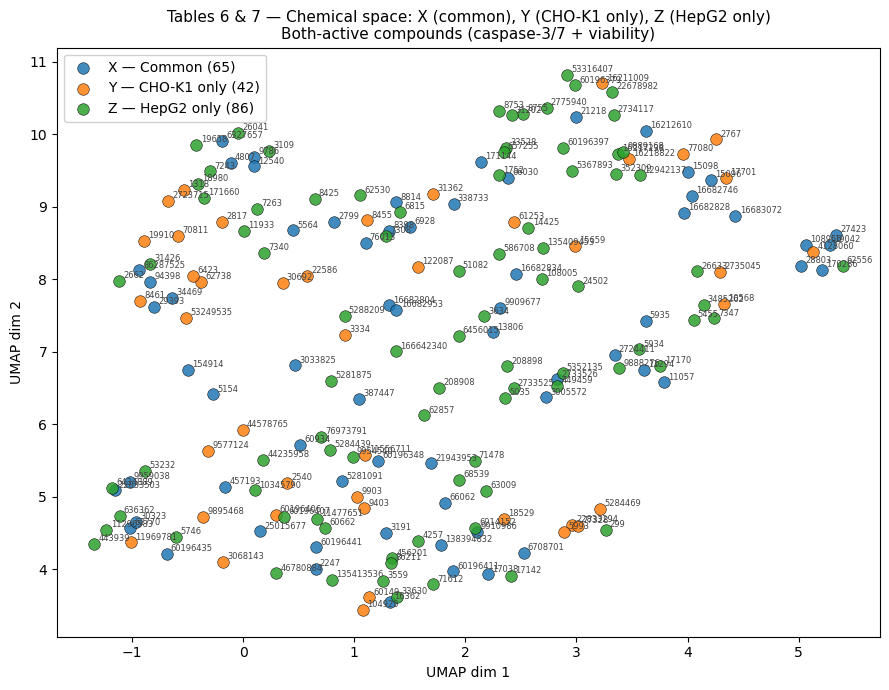

In [7]:
# ── UMAP: X, Y, Z in chemical space ─────────────────────────────────────────
import umap
from rdkit.Chem import rdFingerprintGenerator

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def smiles_list_to_fp(smiles_list):
    mols = [Chem.MolFromSmiles(s) for s in smiles_list if Chem.MolFromSmiles(s)]
    fps  = [gen.GetFingerprint(m) for m in mols]
    return mols, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

# Build combined dataset X+Y+Z
group_rows = []
for grp, cid_set, label in [('X — Common (65)', common_cids, 'X'),
                              ('Y — CHO-K1 only (42)', chok1_only_cids, 'Y'),
                              ('Z — HepG2 only (86)', hepg2_only_cids, 'Z')]:
    for cid in cid_set:
        if cid in smiles_lookup.index:
            group_rows.append({'PUBCHEM_CID': cid, 'smiles': smiles_lookup[cid], 'group': grp, 'label': label})

group_df = pd.DataFrame(group_rows)
group_df['mol'] = group_df['smiles'].apply(lambda s: Chem.MolFromSmiles(s))
group_df = group_df[group_df['mol'].notna()].reset_index(drop=True)
fps_all  = [gen.GetFingerprint(m) for m in group_df['mol']]
fp_mat   = np.array([list(fp.ToBitString()) for fp in fps_all], dtype=np.float32)

N = len(group_df)
reducer = umap.UMAP(n_neighbors=min(15, N-1), min_dist=0.3,
                    metric='jaccard', random_state=42)
emb = reducer.fit_transform(fp_mat)
group_df['umap_x'], group_df['umap_y'] = emb[:, 0], emb[:, 1]

color_map = {'X': '#1f77b4', 'Y': '#ff7f0e', 'Z': '#2ca02c'}
fig, ax = plt.subplots(figsize=(9, 7))
for lbl in ['X', 'Y', 'Z']:
    sub = group_df[group_df['label'] == lbl]
    ax.scatter(sub['umap_x'], sub['umap_y'], c=color_map[lbl],
               s=70, edgecolors='black', linewidths=0.4, alpha=0.85,
               label=sub['group'].iloc[0])
for _, row in group_df.iterrows():
    ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                textcoords='offset points', xytext=(3, 2), fontsize=6, color='#444')
ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
ax.set_title('Tables 6 & 7 — Chemical space: X (common), Y (CHO-K1 only), Z (HepG2 only)\n'
             'Both-active compounds (caspase-3/7 + viability)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout()
plt.show()

In [8]:
# ── Fisher enrichment: Y vs X (what makes CHO-K1-only compounds unique?) ────
enrich_Y_vs_X = fisher_enrichment(
    Y_sets, X_sets,
    label_a='Y_chok1only', label_b='X_common',
    min_count=2, fdr_alpha=0.10   # relax FDR slightly due to small N
)
print(f'Y vs X — Fragments enriched in CHO-K1-only (Y=42) vs Common (X=65): {len(enrich_Y_vs_X)}')
if not enrich_Y_vs_X.empty:
    print(enrich_Y_vs_X[['fragment','n_Y_chok1only','pct_Y_chok1only','n_X_common','pct_X_common','odds_ratio','padj']].head(15).to_string(index=False))

Y vs X — Fragments enriched in CHO-K1-only (Y=42) vs Common (X=65): 0


In [9]:
bar_enrichment(
    enrich_Y_vs_X,
    title='Y vs X — BRICS Fragments Enriched in CHO-K1-only vs Common Both-Active'
)
draw_frags(
    enrich_Y_vs_X,
    title='Y vs X — CHO-K1-selective structural motifs'
)

No significant fragments for: Y vs X — BRICS Fragments Enriched in CHO-K1-only vs Common Both-Active
No drawable fragments for: Y vs X — CHO-K1-selective structural motifs


In [10]:
# ── Fisher enrichment: Z vs X (what makes HepG2-only compounds unique?) ─────
enrich_Z_vs_X = fisher_enrichment(
    Z_sets, X_sets,
    label_a='Z_hepg2only', label_b='X_common',
    min_count=2, fdr_alpha=0.10
)
print(f'Z vs X — Fragments enriched in HepG2-only (Z=86) vs Common (X=65): {len(enrich_Z_vs_X)}')
if not enrich_Z_vs_X.empty:
    print(enrich_Z_vs_X[['fragment','n_Z_hepg2only','pct_Z_hepg2only','n_X_common','pct_X_common','odds_ratio','padj']].head(15).to_string(index=False))

bar_enrichment(
    enrich_Z_vs_X,
    title='Z vs X — BRICS Fragments Enriched in HepG2-only vs Common Both-Active'
)
draw_frags(
    enrich_Z_vs_X,
    title='Z vs X — HepG2-selective structural motifs'
)

Z vs X — Fragments enriched in HepG2-only (Z=86) vs Common (X=65): 0
No significant fragments for: Z vs X — BRICS Fragments Enriched in HepG2-only vs Common Both-Active
No drawable fragments for: Z vs X — HepG2-selective structural motifs


In [11]:
# ── Summary comparison table: fragments appearing in both Y-vs-X and Z-vs-X ──
if not enrich_Y_vs_X.empty and not enrich_Z_vs_X.empty:
    shared = set(enrich_Y_vs_X['fragment']) & set(enrich_Z_vs_X['fragment'])
    y_only_frags = set(enrich_Y_vs_X['fragment']) - set(enrich_Z_vs_X['fragment'])
    z_only_frags = set(enrich_Z_vs_X['fragment']) - set(enrich_Y_vs_X['fragment'])
    print(f'Fragments enriched in BOTH Y and Z vs X: {len(shared)}')
    print(f'Fragments unique to Y (CHO-K1 selective): {len(y_only_frags)}')
    print(f'Fragments unique to Z (HepG2 selective) : {len(z_only_frags)}')
    if shared:
        print('\nShared enriched fragments (enriched in both Y and Z vs X):')
        for f in shared:
            print(f'  {f}')
else:
    print('Insufficient significant results for comparison.')

Insufficient significant results for comparison.


---
## Analysis C — Table 3: Cell-Line Enriched BRICS Fragments

323 compounds are active in at least one of the 14 caspase cell lines.  
We ask: **are there BRICS fragments that significantly appear in compounds active in some cell lines but not others?**

Strategy:
1. For each cell line, define **active** = active in that cell line, **background** = all other active compounds (active in ≥ 1 cell line but not this one)
2. Run Fisher's exact test per cell line
3. Visualise as a heatmap: fragment × cell line → enrichment (log-odds)

Focus on cell lines with N ≥ 10 active compounds (HepG2=241, CHO-K1=115, Jurkat=48, SK-N-SH=19, H-4-II-E=19, HEK293=17, NIH 3T3=12, N2a=7 is borderline).

In [12]:
# ── Load cross-cell-line dataset ────────���────────────────────────────────────
cross = pd.read_csv(BASE + 'results/all_cell_line_comparisions/caspase_atleast_one_active.csv')

AID_COLS = [
    'AID_1346980', 'AID_655', 'AID_656', 'AID_657', 'AID_658',
    'AID_659', 'AID_660', 'AID_661', 'AID_663', 'AID_664',
    'AID_665', 'AID_666', 'AID_667', 'combined_hepg2_casepase.csv'
]
CELL_NAMES = {
    'AID_1346980': 'CHO-K1', 'AID_655': 'Jurkat', 'AID_656': 'HUV-EC-C',
    'AID_657': 'SH-SY5Y', 'AID_658': 'BJ', 'AID_659': 'MRC-5',
    'AID_660': 'Mesangial', 'AID_661': 'SK-N-SH', 'AID_663': 'H-4-II-E',
    'AID_664': 'HEK293', 'AID_665': 'N2a', 'AID_666': 'NIH 3T3',
    'AID_667': 'Renal PT', 'combined_hepg2_casepase.csv': 'HepG2'
}

# Show active counts per cell line
print('Active counts per cell line (in the at-least-one-active set):')
for col in AID_COLS:
    n = (cross[col] == 'Active').sum()
    print(f'  {CELL_NAMES[col]:20s}: {n:3d}')

Active counts per cell line (in the at-least-one-active set):
  CHO-K1              : 115
  Jurkat              :  48
  HUV-EC-C            :   5
  SH-SY5Y             :  10
  BJ                  :   6
  MRC-5               :   8
  Mesangial           :   8
  SK-N-SH             :  19
  H-4-II-E            :  19
  HEK293              :  17
  N2a                 :   7
  NIH 3T3             :  12
  Renal PT            :   8
  HepG2               : 241


In [13]:
# ── Build SMILES lookup for the 323 compounds ────────────────────────────────
# Pull SMILES from cleaned HepG2 and CHO-K1 files (broadest coverage)
smi_sources = [
    BASE + 'cleaned_datasets/combined_hepg2_casepase.csv',
    BASE + 'cleaned_datasets/AID_1346980_cleaned.csv',
    BASE + 'cleaned_datasets/AID_655_cleaned.csv',
    BASE + 'cleaned_datasets/AID_656_cleaned.csv',
    BASE + 'cleaned_datasets/AID_657_cleaned.csv',
    BASE + 'cleaned_datasets/AID_658_cleaned.csv',
    BASE + 'cleaned_datasets/AID_659_cleaned.csv',
    BASE + 'cleaned_datasets/AID_660_cleaned.csv',
    BASE + 'cleaned_datasets/AID_661_cleaned.csv',
    BASE + 'cleaned_datasets/AID_663_cleaned.csv',
    BASE + 'cleaned_datasets/AID_664_cleaned.csv',
    BASE + 'cleaned_datasets/AID_665_cleaned.csv',
    BASE + 'cleaned_datasets/AID_666_cleaned.csv',
    BASE + 'cleaned_datasets/AID_667_cleaned.csv',
]

smi_frames = []
for path in smi_sources:
    try:
        smi_frames.append(pd.read_csv(path,
            usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
            low_memory=False))
    except Exception:
        pass

smi_all = (pd.concat(smi_frames)
             .dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
             .drop_duplicates('PUBCHEM_CID')
             .set_index('PUBCHEM_CID')['PUBCHEM_EXT_DATASOURCE_SMILES'])

cross = cross.merge(
    smi_all.rename('smiles').reset_index(),
    on='PUBCHEM_CID', how='left'
)
cross['frag_set'] = cross['smiles'].apply(
    lambda s: brics_frags(s) if pd.notna(s) else frozenset()
)
cross_valid = cross[cross['frag_set'].apply(len) > 0].reset_index(drop=True)
print(f'Compounds with valid BRICS fragments: {len(cross_valid)} / {len(cross)}')

Compounds with valid BRICS fragments: 323 / 323


In [14]:
# ── Per-cell-line enrichment: active in cell line vs all other active ─────────
# Only run for cell lines with N_active >= 10
MIN_ACTIVE = 10

cellline_results = {}   # col -> significant enriched fragments DataFrame

for col in AID_COLS:
    cname = CELL_NAMES[col]
    active_mask   = cross_valid[col] == 'Active'
    inactive_mask = ~active_mask    # all other compounds in the at-least-one-active set

    n_active = active_mask.sum()
    if n_active < MIN_ACTIVE:
        print(f'Skipping {cname:20s} — only {n_active} active')
        continue

    fg = cross_valid.loc[active_mask, 'frag_set'].tolist()
    bg = cross_valid.loc[inactive_mask, 'frag_set'].tolist()

    res = fisher_enrichment(fg, bg,
                            label_a=cname, label_b='other',
                            min_count=2, fdr_alpha=0.10)
    cellline_results[col] = res
    print(f'{cname:20s}  active={n_active:3d}  enriched fragments={len(res)}')

CHO-K1                active=115  enriched fragments=0
Jurkat                active= 48  enriched fragments=0
Skipping HUV-EC-C             — only 5 active
SH-SY5Y               active= 10  enriched fragments=0
Skipping BJ                   — only 6 active
Skipping MRC-5                — only 8 active
Skipping Mesangial            — only 8 active
SK-N-SH               active= 19  enriched fragments=4
H-4-II-E              active= 19  enriched fragments=8
HEK293                active= 17  enriched fragments=3
Skipping N2a                  — only 7 active
NIH 3T3               active= 12  enriched fragments=4
Skipping Renal PT             — only 8 active
HepG2                 active=241  enriched fragments=0


CHO-K1: no significant enriched fragments
Jurkat: no significant enriched fragments
SH-SY5Y: no significant enriched fragments


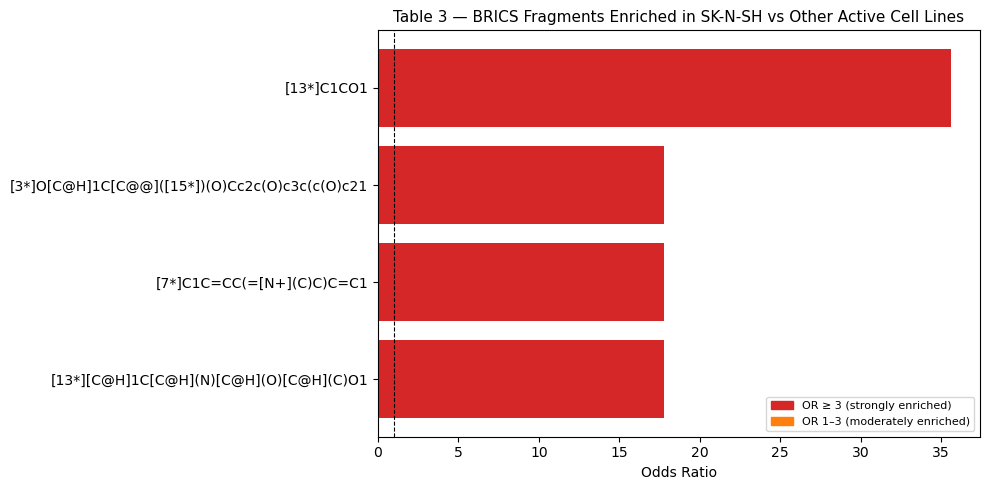


SK-N-SH — Enriched Fragments — top 4 enriched BRICS fragments:


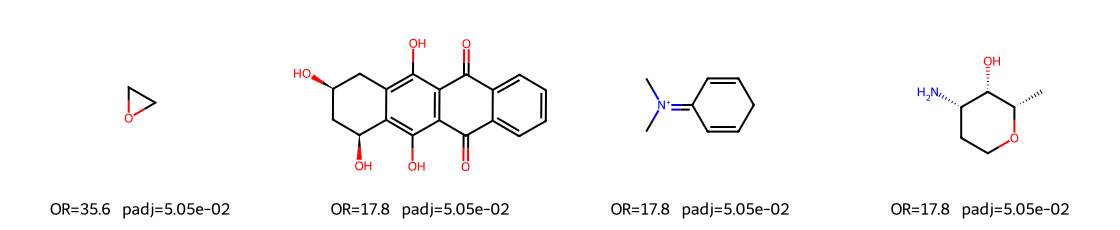

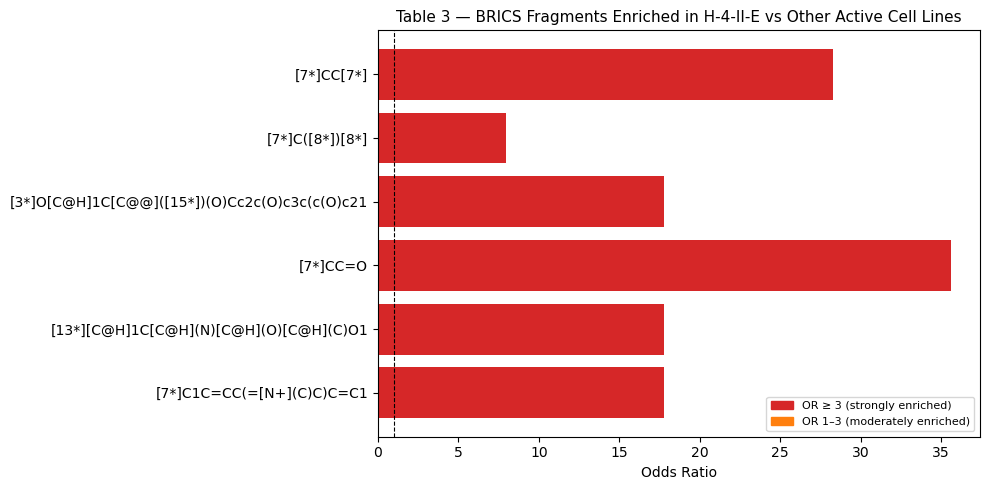


H-4-II-E — Enriched Fragments — top 8 enriched BRICS fragments:


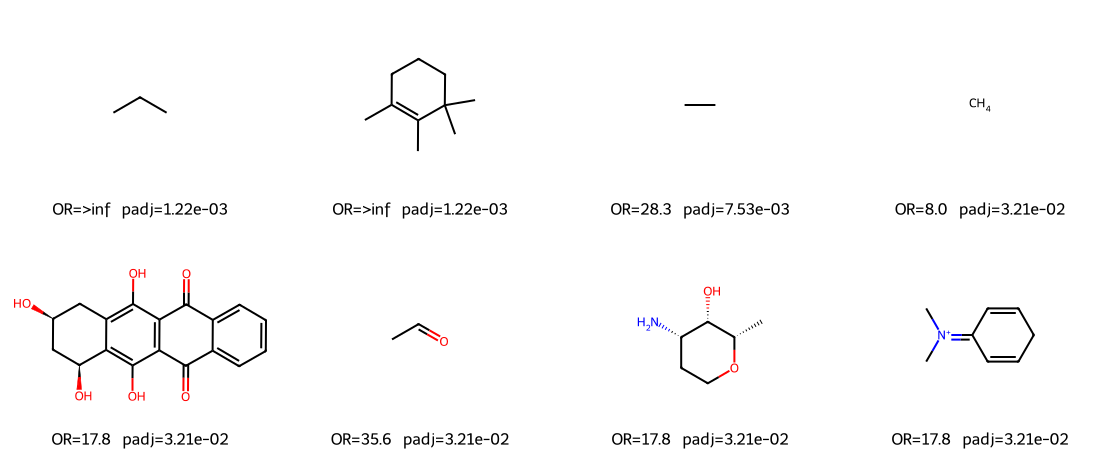

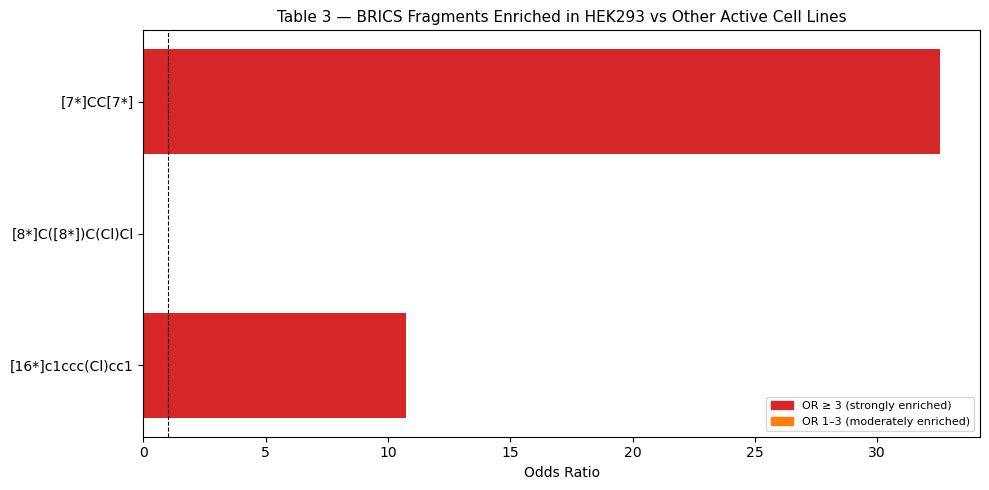


HEK293 — Enriched Fragments — top 3 enriched BRICS fragments:


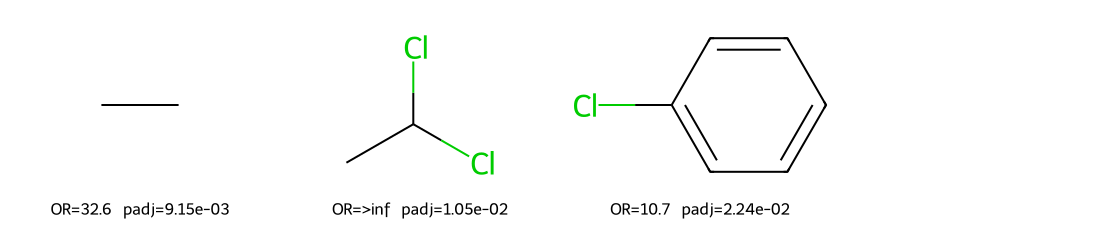

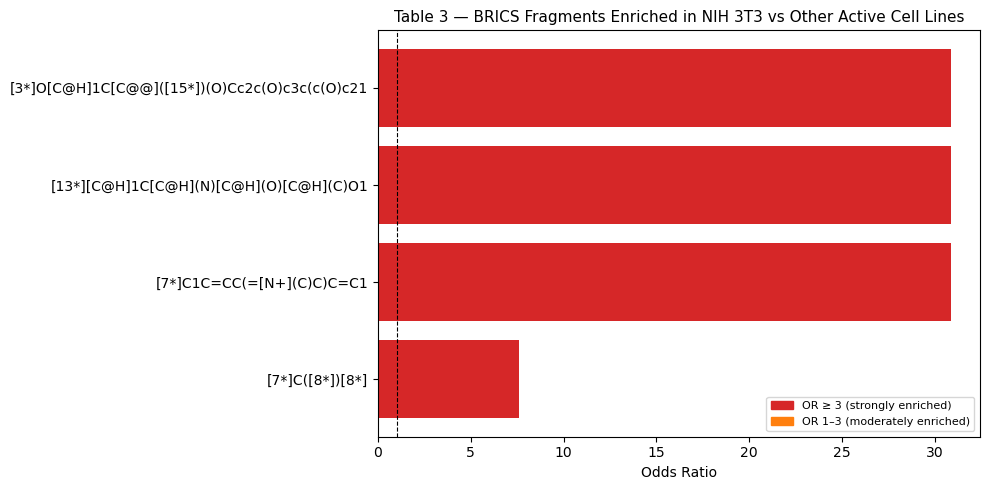


NIH 3T3 — Enriched Fragments — top 4 enriched BRICS fragments:


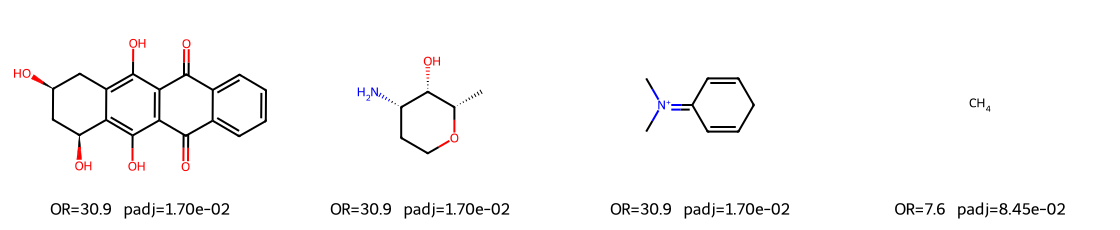

HepG2: no significant enriched fragments


In [15]:
# ── Draw enriched fragments per cell line ────────────────────────────────────
for col, res in cellline_results.items():
    cname = CELL_NAMES[col]
    if res.empty:
        print(f'{cname}: no significant enriched fragments')
        continue
    bar_enrichment(
        res,
        title=f'Table 3 — BRICS Fragments Enriched in {cname} vs Other Active Cell Lines',
        top_n=15
    )
    draw_frags(res, title=f'{cname} — Enriched Fragments', top_n=8, mols_per_row=4)

Total unique significant fragments across all cell lines: 11


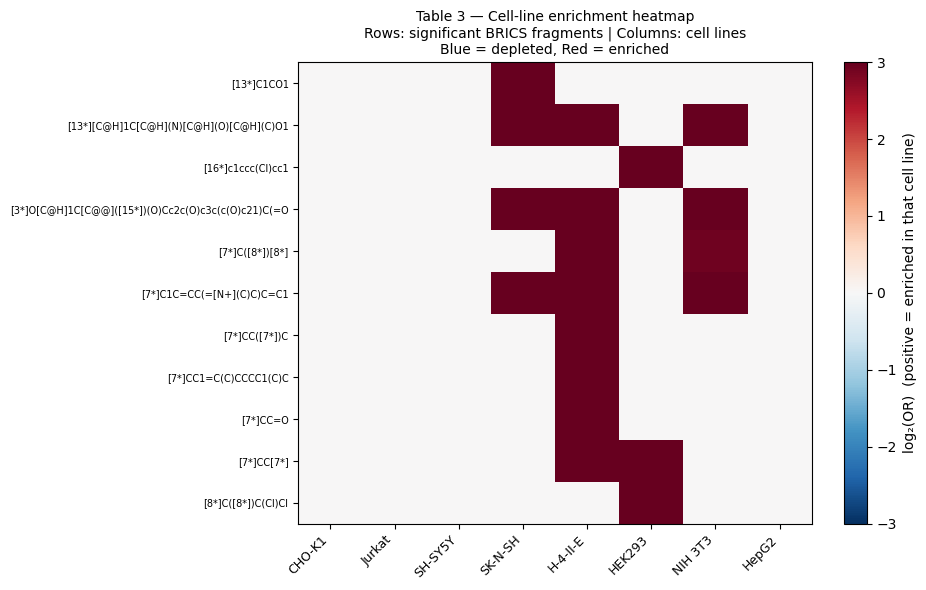

In [16]:
# ── Heatmap: log-odds ratio per fragment × cell line ────────────────────────
# Collect the union of all significant fragments across cell lines
all_sig_frags = set()
for res in cellline_results.values():
    if not res.empty:
        all_sig_frags.update(res['fragment'])

print(f'Total unique significant fragments across all cell lines: {len(all_sig_frags)}')

# Build log-OR matrix
cell_cols_used = [c for c in AID_COLS if c in cellline_results]
cell_names_used = [CELL_NAMES[c] for c in cell_cols_used]

lor_matrix = []
frag_labels = []

for frag in sorted(all_sig_frags):
    row = []
    for col in cell_cols_used:
        res = cellline_results[col]
        if res.empty or frag not in res['fragment'].values:
            row.append(0.0)
        else:
            or_ = res.loc[res['fragment'] == frag, 'odds_ratio'].values[0]
            if or_ == float('inf'):
                row.append(5.0)    # enriched, capped at log2 cap
            elif or_ == 0:
                row.append(-5.0)   # depleted (absent from foreground)
            else:
                row.append(np.log2(or_))
    lor_matrix.append(row)
    frag_labels.append(frag[:50])

lor_arr = np.array(lor_matrix)

if lor_arr.size > 0:
    fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(cell_names_used)),
                                    max(6, 0.4 * len(frag_labels))))
    im = ax.imshow(lor_arr, aspect='auto', cmap='RdBu_r',
                   vmin=-3, vmax=3)
    ax.set_xticks(range(len(cell_names_used)))
    ax.set_xticklabels(cell_names_used, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(frag_labels)))
    ax.set_yticklabels(frag_labels, fontsize=7)
    plt.colorbar(im, ax=ax, label='log₂(OR)  (positive = enriched in that cell line)')
    ax.set_title('Table 3 — Cell-line enrichment heatmap\n'
                 'Rows: significant BRICS fragments | Columns: cell lines\n'
                 'Blue = depleted, Red = enriched', fontsize=10)
    plt.tight_layout()
    plt.show()
else:
    print('No significant fragments found across cell lines.')

In [17]:
# ── Cell-line specificity summary ────────────────────────────────────────────
# Which fragments are unique to ONE cell line vs shared across multiple?
frag_cellline_map = {}   # fragment -> list of cell lines where it is enriched

for col, res in cellline_results.items():
    if res.empty:
        continue
    for frag in res['fragment']:
        frag_cellline_map.setdefault(frag, []).append(CELL_NAMES[col])

print('\n=== Cell-line-specific enriched fragments (unique to 1 cell line) ===')
unique_frags = {f: cls for f, cls in frag_cellline_map.items() if len(cls) == 1}
for frag, cls in sorted(unique_frags.items(), key=lambda x: x[1]):
    print(f'  {cls[0]:20s}  {frag}')

print('\n=== Broadly enriched fragments (in ≥ 3 cell lines) ===')
broad_frags = {f: cls for f, cls in frag_cellline_map.items() if len(cls) >= 3}
for frag, cls in sorted(broad_frags.items(), key=lambda x: -len(x[1])):
    print(f'  {len(cls)} cell lines: {", ".join(cls)}')
    print(f'    Fragment: {frag}')


=== Cell-line-specific enriched fragments (unique to 1 cell line) ===
  H-4-II-E              [7*]CC([7*])C
  H-4-II-E              [7*]CC1=C(C)CCCC1(C)C
  H-4-II-E              [7*]CC=O
  HEK293                [8*]C([8*])C(Cl)Cl
  HEK293                [16*]c1ccc(Cl)cc1
  SK-N-SH               [13*]C1CO1

=== Broadly enriched fragments (in ≥ 3 cell lines) ===
  3 cell lines: SK-N-SH, H-4-II-E, NIH 3T3
    Fragment: [3*]O[C@H]1C[C@@]([15*])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([16*])cccc1C3=O
  3 cell lines: SK-N-SH, H-4-II-E, NIH 3T3
    Fragment: [7*]C1C=CC(=[N+](C)C)C=C1
  3 cell lines: SK-N-SH, H-4-II-E, NIH 3T3
    Fragment: [13*][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1



SK-N-SH — Cell-line-SPECIFIC BRICS fragments (enriched here only) — top 1 enriched BRICS fragments:


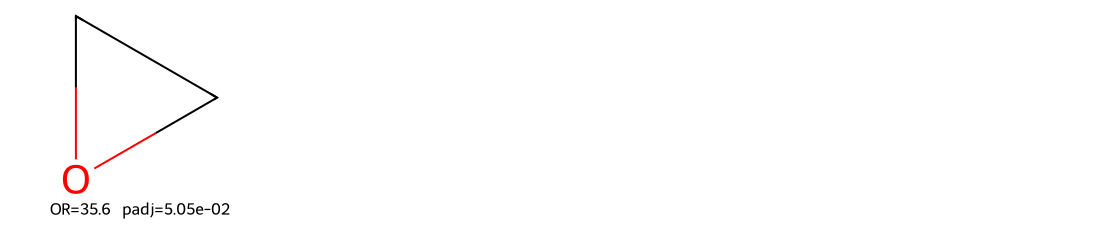


H-4-II-E — Cell-line-SPECIFIC BRICS fragments (enriched here only) — top 3 enriched BRICS fragments:


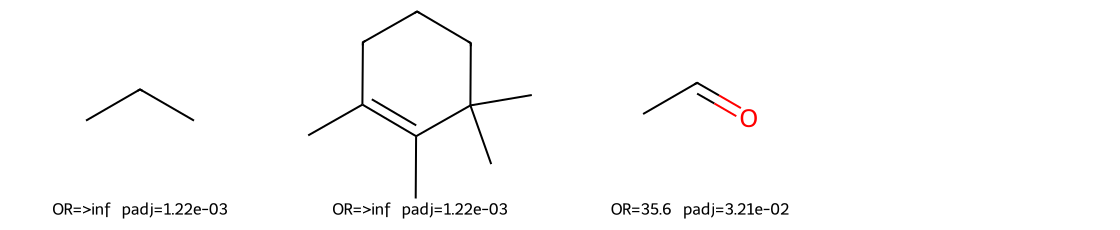


HEK293 — Cell-line-SPECIFIC BRICS fragments (enriched here only) — top 2 enriched BRICS fragments:


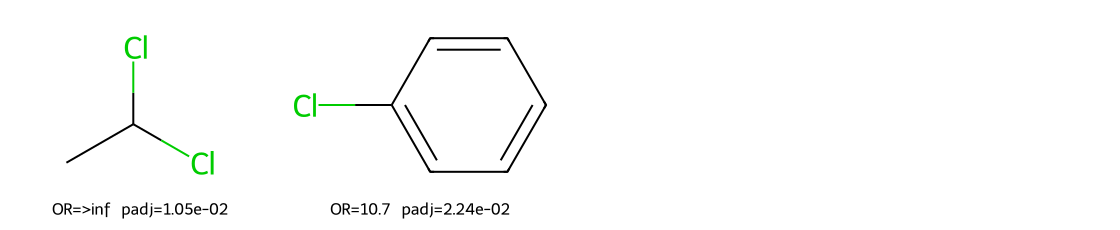

NIH 3T3: no cell-line-specific fragments


In [18]:
# ── Draw cell-line-specific fragments ────────────────────────────────────────
# Group by cell line and show fragments uniquely enriched there
for col, res in cellline_results.items():
    cname = CELL_NAMES[col]
    if res.empty:
        continue
    cell_specific = res[res['fragment'].apply(
        lambda f: len(frag_cellline_map.get(f, [])) == 1)]
    if cell_specific.empty:
        print(f'{cname}: no cell-line-specific fragments')
        continue
    draw_frags(
        cell_specific.reset_index(drop=True),
        title=f'{cname} — Cell-line-SPECIFIC BRICS fragments (enriched here only)',
        top_n=8, mols_per_row=4
    )

In [19]:
# ── PubChem scaffold name lookup ─────────────────────────────────────────────
import json
import urllib.request
import urllib.parse
import time

def pubchem_name(smiles_clean, timeout=10):
    """
    Query PubChem PUG REST for the preferred name of a cleaned fragment SMILES.
    Returns (CID, preferred_name, iupac_name).
    Falls back to synonyms list when Title is absent.
    """
    mol = Chem.MolFromSmiles(smiles_clean)
    canon = Chem.MolToSmiles(mol) if mol else smiles_clean
    enc  = urllib.parse.quote(canon, safe='')
    base = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{enc}"
    try:
        # 1st try: property endpoint (Title + IUPACName)
        with urllib.request.urlopen(
                f"{base}/property/IUPACName,Title/JSON", timeout=timeout) as r:
            p = json.loads(r.read())['PropertyTable']['Properties'][0]
        cid   = p.get('CID')
        title = p.get('Title') or p.get('IUPACName')
        iupac = p.get('IUPACName')
        if title:
            return cid, title, iupac
        # Fallback: synonyms (first entry = most common deposited name)
        with urllib.request.urlopen(
                f"{base}/synonyms/JSON", timeout=timeout) as r:
            syns = json.loads(r.read())['InformationList']['Information'][0].get('Synonym', [])
        return cid, syns[0] if syns else None, iupac
    except Exception as e:
        return None, None, f'error: {e}'

def name_enriched_fragments(enrich_df, label='', pause=0.25):
    """
    Attach PubChem names to every enriched BRICS fragment.
    Returns a DataFrame: fragment, cleaned_smiles, CID, preferred_name, iupac_name, OR, padj.
    """
    if enrich_df.empty:
        print(f'{label}: no fragments to name.')
        return pd.DataFrame()

    rows = []
    for _, row in enrich_df.iterrows():
        cleaned = clean_frag(row['fragment'])
        cid, title, iupac = pubchem_name(cleaned)
        rows.append({
            'fragment':       row['fragment'],
            'cleaned_smiles': cleaned,
            'pubchem_cid':    cid,
            'preferred_name': title,
            'iupac_name':     iupac,
            'odds_ratio':     row['odds_ratio'],
            'padj':           row['padj'],
        })
        time.sleep(pause)

    result = pd.DataFrame(rows)
    print(f'\n{label}')
    display_cols = ['preferred_name', 'iupac_name', 'odds_ratio', 'padj', 'cleaned_smiles']
    print(result[display_cols].to_string(index=False))
    return result

# ── Run for all three analyses ───────────────────────────────────────────────
print('=== Table 4: Both-Active (caspase + mito, HepG2) ===')
names_t4 = name_enriched_fragments(enrich_t4, label='Table 4 — Both Active (HepG2)')

print('\n=== Table 4 Reverse: Both-Inactive ===')
names_t4_inv = name_enriched_fragments(enrich_t4_inv, label='Table 4 — Both Inactive (HepG2)')

print('\n=== Y vs X: CHO-K1-only vs Common ===')
names_Y = name_enriched_fragments(enrich_Y_vs_X, label='Y vs X — CHO-K1-selective')

print('\n=== Z vs X: HepG2-only vs Common ===')
names_Z = name_enriched_fragments(enrich_Z_vs_X, label='Z vs X — HepG2-selective')

print('\n=== Table 3: Per-cell-line enriched fragments ===')
cellline_names = {}
for col, res in cellline_results.items():
    cname = CELL_NAMES[col]
    cellline_names[col] = name_enriched_fragments(res, label=f'{cname} enriched fragments')


=== Table 4: Both-Active (caspase + mito, HepG2) ===

Table 4 — Both Active (HepG2)
                      preferred_name                              iupac_name  odds_ratio         padj                                                    cleaned_smiles
                              Phenol                                  phenol   12.483254 5.022764e-07                                                    [H]c1ccc(O)cc1
                                None error: HTTP Error 404: PUGREST.NotFound         inf 5.948294e-05 [H]O[C@H]1C[C@@]([H])(O)Cc2c(O)c3c(c(O)c21)C(=O)c1c([H])cccc1C3=O
                              Phenol                                  phenol   47.230216 5.948294e-05                                               [H]c1ccc(O)c([H])c1
(2S,3S,4S)-4-amino-2-methyloxan-3-ol    (2S,3S,4S)-4-amino-2-methyloxan-3-ol         inf 5.948294e-05                              [H][C@H]1C[C@H](N)[C@H](O)[C@H](C)O1
                            M-Cresol                          3-methylphenol

In [20]:
# ── Generate fragment PNG images for LaTeX table ─────────────────────────────
import os
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import display, SVG

FIGS = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/'
os.makedirs(FIGS, exist_ok=True)

# (filename, SMILES, label)
# Notes on rendering choices:
#   frag_hydroxyphenyl : [*]c1ccc(O)c([*])c1 — phenol ring with two aromatic
#                        attachment points (1,3-disubstituted pattern from BRICS [16*]c1ccc(O)c([16*])c1)
#   frag_methylene     : [8*]C[8*] → shown as propane (CCC) to make -CH2- visible
#   frag_methine       : [7*]C([8*])[8*] → shown as isobutane to make -CH< visible
#   frag_dodecyl_alt   : [4*] attachment variant of dodecyl — same chain, different
#                        BRICS bond type; shown as dodecane
FRAG_DEFS = [
    ('frag_phenol',          'Oc1ccccc1',                          'Para-hydroxyphenyl (phenol)'),
    ('frag_hydroxyphenyl',   '[*]c1ccc(O)c([*])c1',                'Disubstituted hydroxyphenyl'),
    ('frag_mcresol',         'Cc1cccc(O)c1',                       'm-Cresol (3-methylphenol)'),
    ('frag_isobutyl',        'CC(C)C',                             'Isobutyl (branched C4)'),
    ('frag_trimethylpentyl', 'CC(C)CC(C)(C)C',                     '2,2,4-Trimethylpentyl (branched C8)'),
    ('frag_methylene',       'CCC',                                 'Methylene bridge (-CH2-)'),
    ('frag_octyl',           'CCCCCCCC',                           'Octyl chain (linear C8)'),
    ('frag_dodecyl',         'CCCCCCCCCCCC',                       'Dodecyl chain (linear C12)'),
    ('frag_methine',         'CC(C)C',                             'Methine carbon (-CH<)'),
    ('frag_dodecyl_alt',     'CCCCCCCCCCCC',                       'Dodecyl chain alt. (linear C12)'),
    ('frag_aminosugar',      'C[C@@H]1OCC[C@H](N)[C@@H]1O',        'Aminosugar moiety'),
    ('frag_anthracycline',   'OC1CC(O)Cc2c(O)c3c(c(O)c21)C(=O)c1ccccc1C3=O', 'Anthracycline ring system'),
    ('frag_organotin',       'O[Sn](CCC)(CCC)CCC',                 'Trialkyltin (tributyltin)'),
    ('frag_dimethylamine',   'CN(C)C',                             'Dimethylamine (tertiary amine)'),
    ('frag_methylamine',     'CN',                                  'Methylamine (secondary amine)'),
    ('frag_cf3',             'FC(F)F',                             'Trifluoromethyl'),
]

failed = []
for fname, smi, label in FRAG_DEFS:
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        print(f'  INVALID SMILES: {fname} — {smi}')
        failed.append(fname)
        continue

    # PNG via cairo
    d = rdMolDraw2D.MolDraw2DCairo(200, 200)
    d.drawOptions().addStereoAnnotation = False
    d.drawOptions().padding = 0.15
    d.DrawMolecule(mol)
    d.FinishDrawing()
    with open(f'{FIGS}{fname}.png', 'wb') as f:
        f.write(d.GetDrawingText())

    # SVG preview in notebook
    d2 = rdMolDraw2D.MolDraw2DSVG(160, 160)
    d2.drawOptions().addStereoAnnotation = False
    d2.DrawMolecule(mol)
    d2.FinishDrawing()

    print(f'  Saved {fname}.png  —  {label}')

if not failed:
    print(f'\nAll {len(FRAG_DEFS)} fragment images saved to {FIGS}')
else:
    print(f'\nFailed: {failed}')


  Saved frag_phenol.png  —  Para-hydroxyphenyl (phenol)
  Saved frag_hydroxyphenyl.png  —  Disubstituted hydroxyphenyl
  Saved frag_mcresol.png  —  m-Cresol (3-methylphenol)
  Saved frag_isobutyl.png  —  Isobutyl (branched C4)
  Saved frag_trimethylpentyl.png  —  2,2,4-Trimethylpentyl (branched C8)
  Saved frag_methylene.png  —  Methylene bridge (-CH2-)
  Saved frag_octyl.png  —  Octyl chain (linear C8)
  Saved frag_dodecyl.png  —  Dodecyl chain (linear C12)
  Saved frag_methine.png  —  Methine carbon (-CH<)
  Saved frag_dodecyl_alt.png  —  Dodecyl chain alt. (linear C12)
  Saved frag_aminosugar.png  —  Aminosugar moiety
  Saved frag_anthracycline.png  —  Anthracycline ring system
  Saved frag_organotin.png  —  Trialkyltin (tributyltin)
  Saved frag_dimethylamine.png  —  Dimethylamine (tertiary amine)
  Saved frag_methylamine.png  —  Methylamine (secondary amine)
  Saved frag_cf3.png  —  Trifluoromethyl

All 16 fragment images saved to /Users/yaminichitikela/Documents/casepase/Casepase

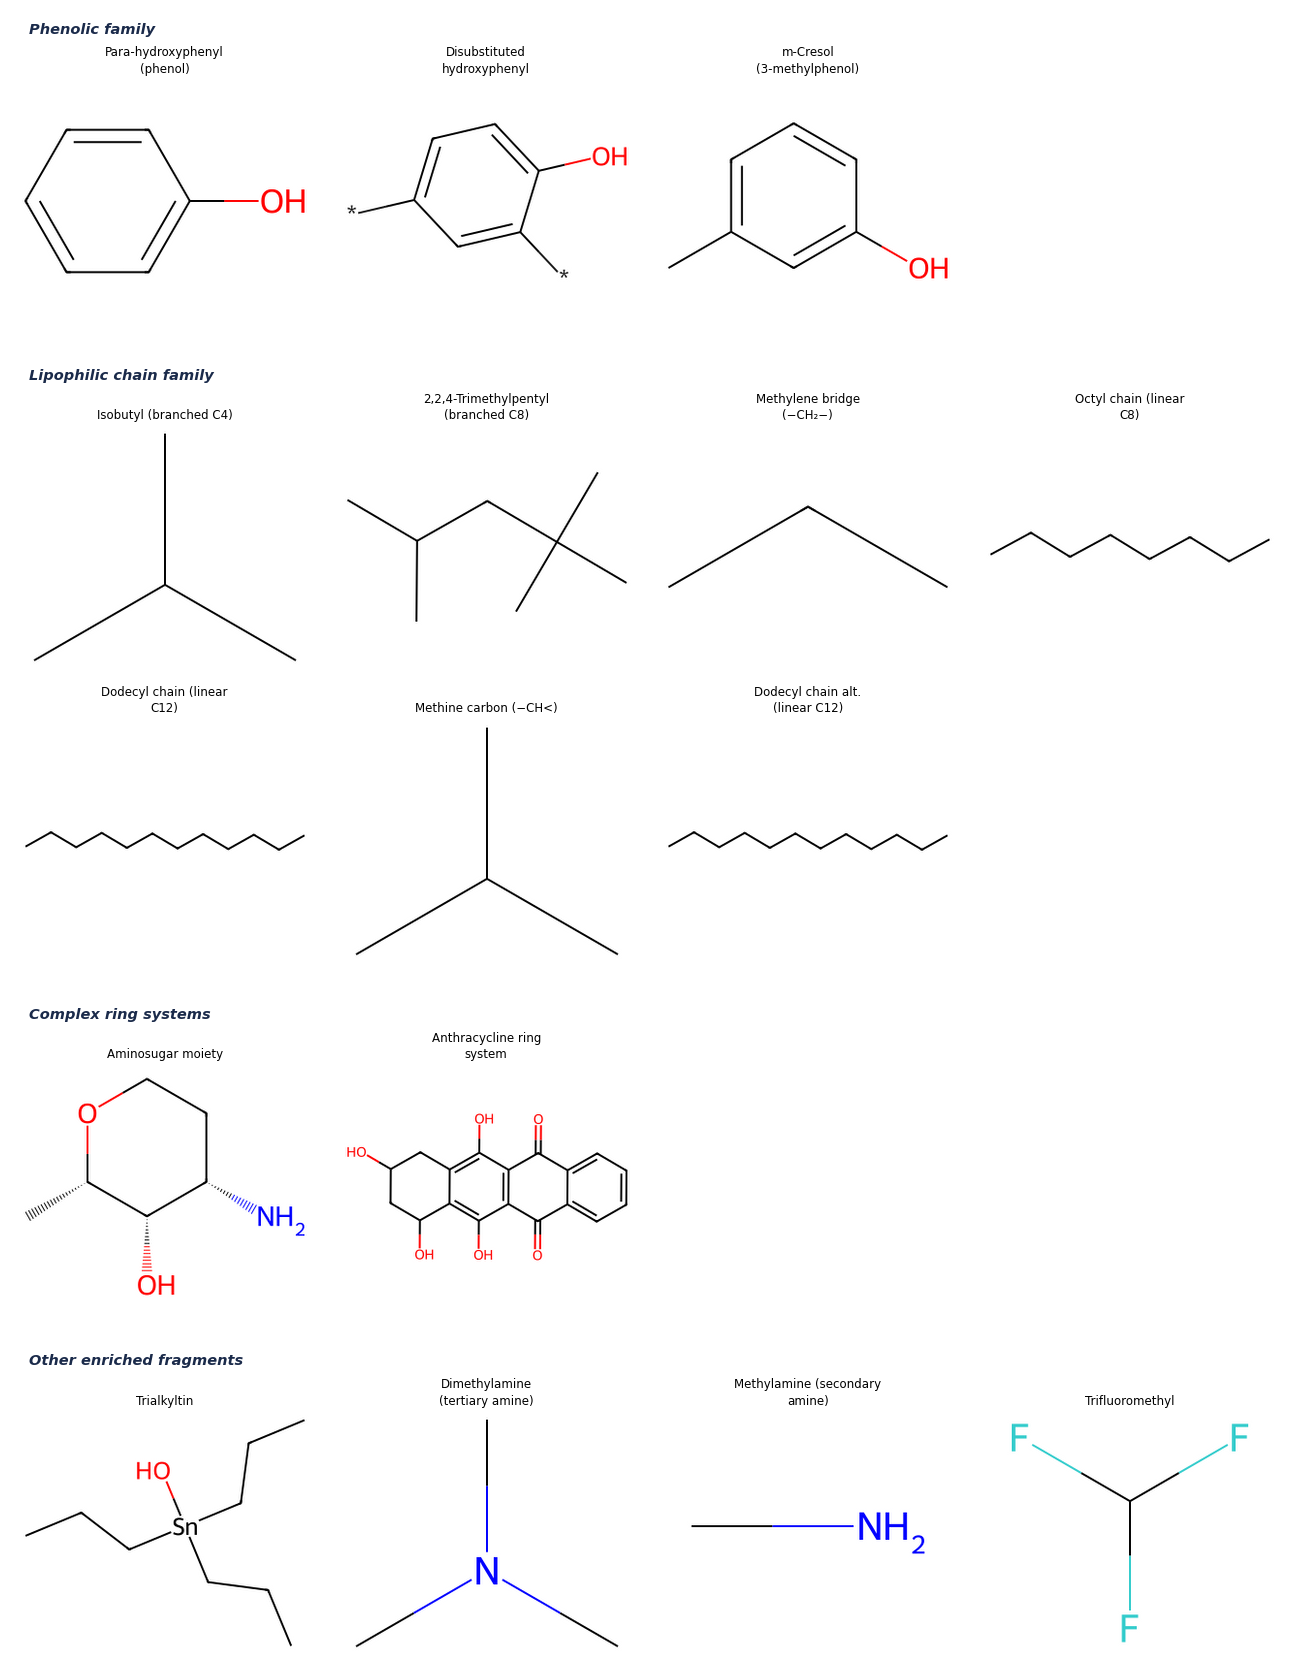

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_brics_enriched_fragments.png


In [24]:
# ── Main-text figure: all 16 enriched BRICS fragments with names ─────────────
# Generates fig_brics_enriched_fragments.png for inclusion in the paper body.
# Structures are grouped by family (header rows) and drawn at a legible size.

import os, textwrap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import Draw

FIGS = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/'
os.makedirs(FIGS, exist_ok=True)

# ── Fragment definitions grouped by family ────────────────────────────────────
FAMILIES = [
    ('Phenolic family', [
        ('Para-hydroxyphenyl (phenol)',          'Oc1ccccc1'),
        ('Disubstituted hydroxyphenyl',          '[*]c1ccc(O)c([*])c1'),
        ('m-Cresol (3-methylphenol)',            'Cc1cccc(O)c1'),
    ]),
    ('Lipophilic chain family', [
        ('Isobutyl (branched C4)',               'CC(C)C'),
        ('2,2,4-Trimethylpentyl (branched C8)', 'CC(C)CC(C)(C)C'),
        ('Methylene bridge (\u2212CH\u2082\u2212)', 'CCC'),
        ('Octyl chain (linear C8)',              'CCCCCCCC'),
        ('Dodecyl chain (linear C12)',           'CCCCCCCCCCCC'),
        ('Methine carbon (\u2212CH<)',           'CC(C)C'),
        ('Dodecyl chain alt. (linear C12)',      'CCCCCCCCCCCC'),
    ]),
    ('Complex ring systems', [
        ('Aminosugar moiety',                    'C[C@@H]1OCC[C@H](N)[C@@H]1O'),
        ('Anthracycline ring system',            'OC1CC(O)Cc2c(O)c3c(c(O)c21)C(=O)c1ccccc1C3=O'),
    ]),
    ('Other enriched fragments', [
        ('Trialkyltin',                          'O[Sn](CCC)(CCC)CCC'),
        ('Dimethylamine (tertiary amine)',       'CN(C)C'),
        ('Methylamine (secondary amine)',        'CN'),
        ('Trifluoromethyl',                      'FC(F)F'),
    ]),
]

NCOLS  = 4
IMG_W, IMG_H = 320, 260   # px per molecule panel

def smiles_to_rgb(smi, w=IMG_W, h=IMG_H):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((h, w, 3), dtype=np.uint8) * 255
    img = Draw.MolToImage(mol, size=(w, h))
    return np.asarray(img.convert('RGB'))

# ── Build row plan ─────────────────────────────────────────────────────────────
# Each entry is ('header', title_str) or ('mols', [(label, arr), ...])
row_plan = []
for fam_name, frags in FAMILIES:
    row_plan.append(('header', fam_name))
    for chunk_start in range(0, len(frags), NCOLS):
        chunk = frags[chunk_start : chunk_start + NCOLS]
        row_plan.append(('mols', [(lbl, smiles_to_rgb(smi)) for lbl, smi in chunk]))

# ── Figure geometry ────────────────────────────────────────────────────────────
H_HDR = 0.42   # inches for a header row
H_MOL = 3.0    # inches for a molecule row
FIG_W = NCOLS * 3.25

height_ratios = [H_HDR if rp[0] == 'header' else H_MOL for rp in row_plan]
fig_h = sum(height_ratios) + 0.3   # small top/bottom margin

fig = plt.figure(figsize=(FIG_W, fig_h), facecolor='white')
gs  = gridspec.GridSpec(
    len(row_plan), NCOLS, figure=fig,
    height_ratios=height_ratios,
    hspace=0.08, wspace=0.04,
    left=0.01, right=0.99, top=0.99, bottom=0.01,
)

HDR_COLOUR  = '#FFFF'
HDR_EDGE    = '#FFF'
TITLE_FONT  = 8.5
HDR_FONT    = 10.5

for ri, rp in enumerate(row_plan):
    if rp[0] == 'header':
        ax = fig.add_subplot(gs[ri, :])
        ax.set_facecolor(HDR_COLOUR)
        for spine in ax.spines.values():
            spine.set_edgecolor(HDR_EDGE)
            spine.set_linewidth(0.8)
        ax.text(0.015, 0.5, rp[1],
                transform=ax.transAxes,
                fontsize=HDR_FONT, fontweight='bold', fontstyle='italic',
                va='center', ha='left', color='#1A2A4A')
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xticks([]); ax.set_yticks([])
    else:
        cells = rp[1]
        for ci in range(NCOLS):
            ax = fig.add_subplot(gs[ri, ci])
            ax.axis('off')
            if ci < len(cells):
                label, arr = cells[ci]
                ax.imshow(arr, aspect='equal', interpolation='lanczos')
                wrapped = '\n'.join(textwrap.wrap(label, width=22))
                ax.set_title(wrapped, fontsize=TITLE_FONT, pad=3,
                             multialignment='center', linespacing=1.35)
            # empty slots stay invisible

out = FIGS + 'fig_brics_enriched_fragments.png'
fig.savefig(out, dpi=250, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved → {out}')

In [22]:
# ── Generate fragment PNG images for Analysis C LaTeX table ──────────────────
import os
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

FIGS = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/'
os.makedirs(FIGS, exist_ok=True)

# (filename, canonical SMILES, label)
FRAG_DEFS_C = [
    # Shared across SK-N-SH, H-4-II-E, NIH 3T3
    ('c_frag_aminosugar',      'C[C@@H]1OCC[C@H](N)[C@@H]1O',                        'Aminosugar moiety'),
    ('c_frag_dimethylcd',      'C[N+](C)=C1C=CCC=C1',                                'Dimethylaminocyclohexadiene'),
    ('c_frag_anthracycline',   'O=C1c2ccccc2C(=O)c2c(O)c3c(c(O)c21)C[C@H](O)C[C@@H]3O',       'Anthracycline ring system'),
    # SK-N-SH unique
    ('c_frag_epoxide',         'C1CO1',                                               'Epoxide'),
    # H-4-II-E unique
    ('c_frag_tmcyclohex',      'CC1=C(C)C(C)(C)CCC1',                                '1,2,3,3-Tetramethylcyclohexene'),
    ('c_frag_acetaldehyde',    'CC=O',                                                'Acetaldehyde'),
    # HEK293 unique
    ('c_frag_dichloroethane',  'CC(Cl)Cl',                                            '1,1-Dichloroethane'),
    ('c_frag_chlorobenzene',   'Clc1ccccc1',                                          'Chlorobenzene'),
]

for fname, smi, label in FRAG_DEFS_C:
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        print(f'INVALID SMILES: {fname} — {smi}')
        continue
    d = rdMolDraw2D.MolDraw2DCairo(200, 200)
    d.drawOptions().addStereoAnnotation = False
    d.drawOptions().padding = 0.15
    d.DrawMolecule(mol)
    d.FinishDrawing()
    with open(f'{FIGS}{fname}.png', 'wb') as f:
        f.write(d.GetDrawingText())
    print(f'Saved {fname}.png  —  {label}')

print(f'\nAll {len(FRAG_DEFS_C)} Analysis C fragment images saved to {FIGS}')


Saved c_frag_aminosugar.png  —  Aminosugar moiety
Saved c_frag_dimethylcd.png  —  Dimethylaminocyclohexadiene
Saved c_frag_anthracycline.png  —  Anthracycline ring system
Saved c_frag_epoxide.png  —  Epoxide
Saved c_frag_tmcyclohex.png  —  1,2,3,3-Tetramethylcyclohexene
Saved c_frag_acetaldehyde.png  —  Acetaldehyde
Saved c_frag_dichloroethane.png  —  1,1-Dichloroethane
Saved c_frag_chlorobenzene.png  —  Chlorobenzene

All 8 Analysis C fragment images saved to /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/


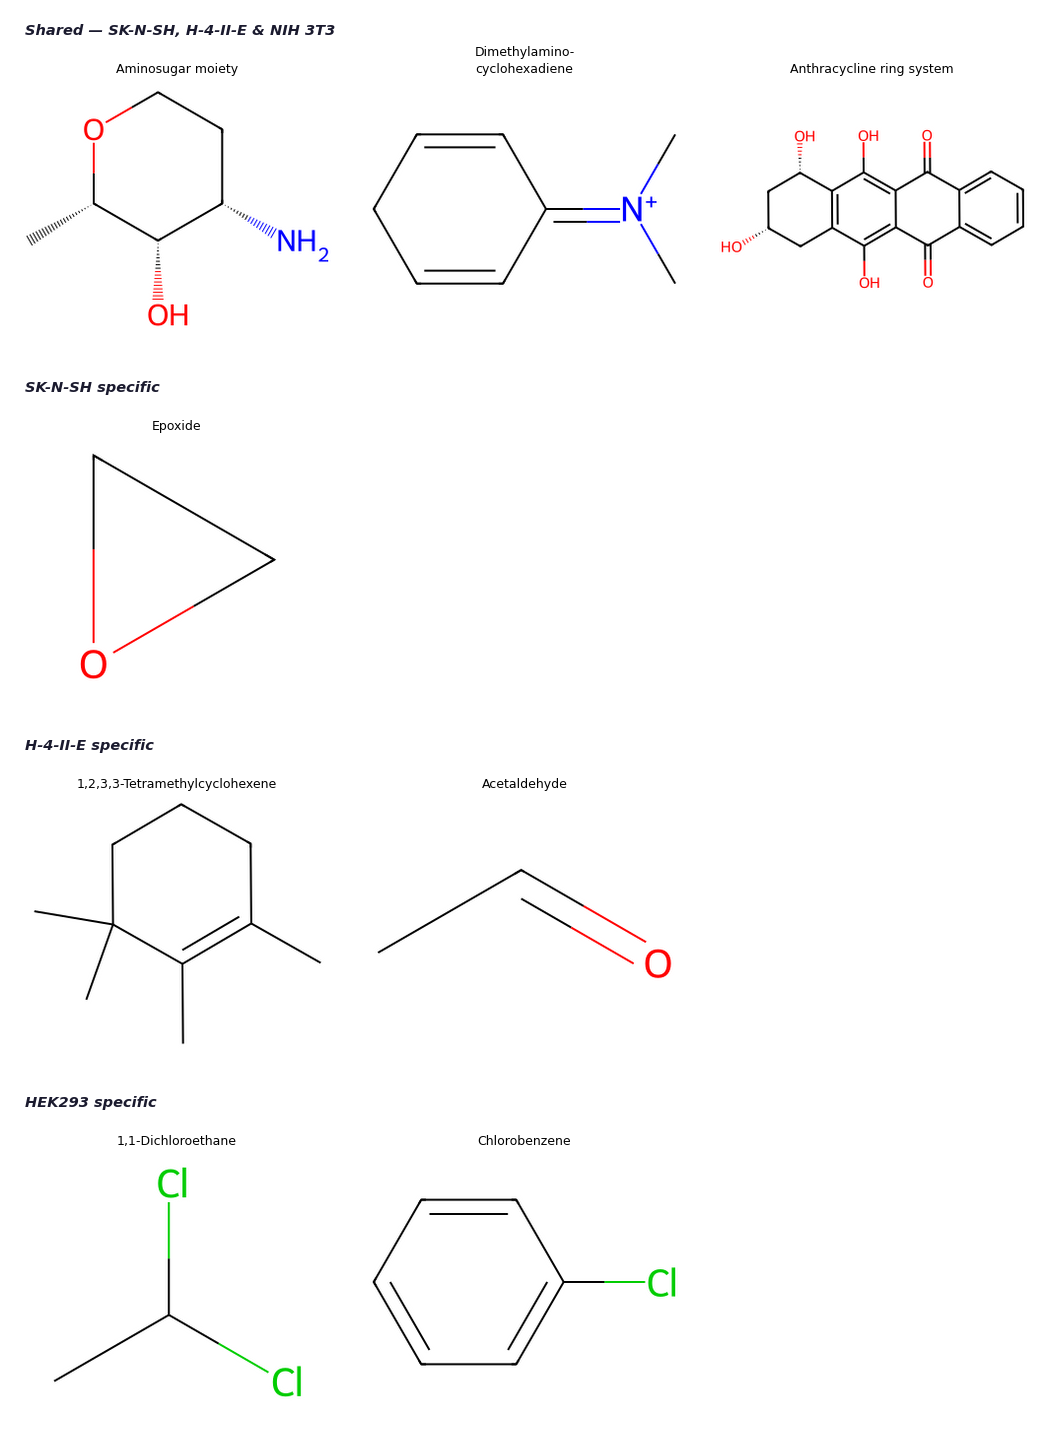

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_brics_cellline_fragments.png


In [26]:
# ── Main-text figure: cell-line-specific BRICS fragments ─────────────────────
# Groups the 8 enriched fragments by which cell line(s) they appear in.
# Saves fig_brics_cellline_fragments.png for the paper body.

import os, textwrap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import Draw

FIGS = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/'
os.makedirs(FIGS, exist_ok=True)

# ── Fragment definitions grouped by cell-line association ─────────────────────
# SMILES verified against actual BRICS fragment output (canonical via RDKit).
# Anthracycline uses stereo-correct SMILES from BRICS decomposition.
FAMILIES = [
    ('Shared — SK-N-SH, H-4-II-E & NIH 3T3', [
        ('Aminosugar moiety',                  'C[C@@H]1OCC[C@H](N)[C@@H]1O'),
        ('Dimethylamino-\ncyclohexadiene',     'C[N+](C)=C1C=CCC=C1'),
        ('Anthracycline ring system',           'O=C1c2ccccc2C(=O)c2c(O)c3c(c(O)c21)C[C@H](O)C[C@@H]3O'),
    ]),
    ('SK-N-SH specific', [
        ('Epoxide',                             'C1CO1'),
    ]),
    ('H-4-II-E specific', [
        ('1,2,3,3-Tetramethylcyclohexene',      'CC1=C(C)C(C)(C)CCC1'),
        ('Acetaldehyde',                        'CC=O'),
    ]),
    ('HEK293 specific', [
        ('1,1-Dichloroethane',                  'CC(Cl)Cl'),
        ('Chlorobenzene',                       'Clc1ccccc1'),
    ]),
]

NCOLS  = 3
IMG_W, IMG_H = 340, 270

def smiles_to_rgb(smi, w=IMG_W, h=IMG_H):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((h, w, 3), dtype=np.uint8) * 255
    img = Draw.MolToImage(mol, size=(w, h))
    return np.asarray(img.convert('RGB'))

# ── Build row plan ─────────────────────────────────────────────────────────────
row_plan = []
for fam_name, frags in FAMILIES:
    row_plan.append(('header', fam_name))
    for chunk_start in range(0, len(frags), NCOLS):
        chunk = frags[chunk_start : chunk_start + NCOLS]
        row_plan.append(('mols', [(lbl, smiles_to_rgb(smi)) for lbl, smi in chunk]))

# ── Figure geometry ────────────────────────────────────────────────────────────
H_HDR = 0.44
H_MOL = 3.1
FIG_W = NCOLS * 3.5

height_ratios = [H_HDR if rp[0] == 'header' else H_MOL for rp in row_plan]
fig_h = sum(height_ratios) + 0.3

fig = plt.figure(figsize=(FIG_W, fig_h), facecolor='white')
gs  = gridspec.GridSpec(
    len(row_plan), NCOLS, figure=fig,
    height_ratios=height_ratios,
    hspace=0.08, wspace=0.04,
    left=0.01, right=0.99, top=0.99, bottom=0.01,
)

# ── Colour palette: one per cell-line group ────────────────────────────────────
HDR_COLOURS = ['#FFF', '#FFF', '#FFF', '#FFF']
HDR_EDGES   = ['#FFF', '#FFF', '#FFF', '#FFF']
hdr_idx = 0

for ri, rp in enumerate(row_plan):
    if rp[0] == 'header':
        ax = fig.add_subplot(gs[ri, :])
        ax.set_facecolor(HDR_COLOURS[hdr_idx])
        for spine in ax.spines.values():
            spine.set_edgecolor(HDR_EDGES[hdr_idx])
            spine.set_linewidth(0.8)
        ax.text(0.015, 0.5, rp[1],
                transform=ax.transAxes,
                fontsize=10.5, fontweight='bold', fontstyle='italic',
                va='center', ha='left', color='#1A1A2E')
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xticks([]); ax.set_yticks([])
        hdr_idx += 1
    else:
        cells = rp[1]
        for ci in range(NCOLS):
            ax = fig.add_subplot(gs[ri, ci])
            ax.axis('off')
            if ci < len(cells):
                label, arr = cells[ci]
                ax.imshow(arr, aspect='equal', interpolation='lanczos')
                wrapped = label.replace('\\n', '\n') if '\\n' in label else '\n'.join(textwrap.wrap(label, width=26, break_long_words=False))
                ax.set_title(wrapped, fontsize=9.0, pad=3,
                             multialignment='center', linespacing=1.35)

out = FIGS + 'fig_brics_cellline_fragments.png'
fig.savefig(out, dpi=250, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved \u2192 {out}')

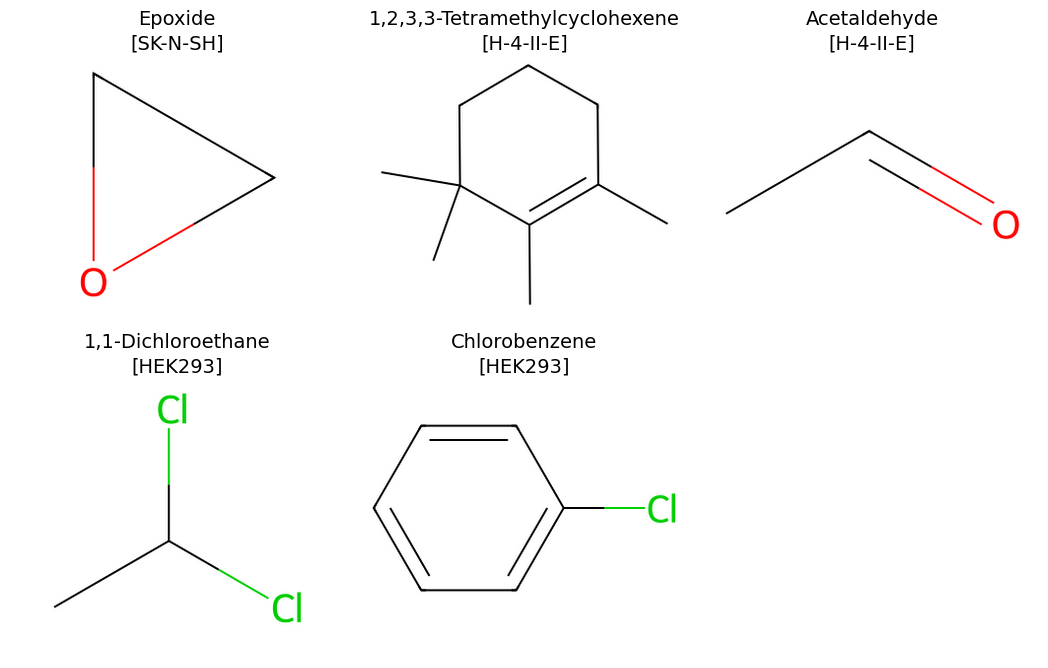

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/fig_brics_cellline_specific_only.png


In [30]:
# ── Main-text figure: cell-line-SPECIFIC BRICS fragments only (compact grid) ──
# Fragments shared across ≥3 cell lines removed. All 5 specific fragments laid
# out in a flat 3-per-row grid; cell-line label folded into each molecule title.

import os, textwrap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import Draw

FIGS = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/figures/'
os.makedirs(FIGS, exist_ok=True)

# ── All cell-line-specific fragments (cell line embedded in label) ─────────────
ALL_FRAGS = [
    ('Epoxide\n[SK-N-SH]',                      'C1CO1'),
    ('1,2,3,3-Tetramethylcyclohexene\n[H-4-II-E]', 'CC1=C(C)C(C)(C)CCC1'),
    ('Acetaldehyde\n[H-4-II-E]',                'CC=O'),
    ('1,1-Dichloroethane\n[HEK293]',             'CC(Cl)Cl'),
    ('Chlorobenzene\n[HEK293]',                  'Clc1ccccc1'),
]

NCOLS   = 3
IMG_W, IMG_H = 340, 270

def smiles_to_rgb(smi, w=IMG_W, h=IMG_H):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return np.ones((h, w, 3), dtype=np.uint8) * 255
    img = Draw.MolToImage(mol, size=(w, h))
    return np.asarray(img.convert('RGB'))

# ── Build rows of NCOLS ────────────────────────────────────────────────────────
rows = [ALL_FRAGS[i:i+NCOLS] for i in range(0, len(ALL_FRAGS), NCOLS)]
rendered = [[(lbl, smiles_to_rgb(smi)) for lbl, smi in row] for row in rows]

# ── Figure geometry ────────────────────────────────────────────────────────────
H_MOL  = 3.1
FIG_W  = NCOLS * 3.5
nrows  = len(rows)
fig_h  = nrows * H_MOL + 0.15

fig = plt.figure(figsize=(FIG_W, fig_h), facecolor='white')
gs  = gridspec.GridSpec(
    nrows, NCOLS, figure=fig,
    hspace=0.08, wspace=0.04,
    left=0.01, right=0.99, top=0.99, bottom=0.01,
)

for ri, row_cells in enumerate(rendered):
    for ci in range(NCOLS):
        ax = fig.add_subplot(gs[ri, ci])
        ax.axis('off')
        if ci < len(row_cells):
            label, arr = row_cells[ci]
            ax.imshow(arr, aspect='equal', interpolation='lanczos')
            ax.set_title(label, fontsize=14.0, pad=3,
                         multialignment='center', linespacing=1.35)

out = FIGS + 'fig_brics_cellline_specific_only.png'
fig.savefig(out, dpi=250, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved \u2192 {out}')